In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
# Define project paths
PROJECT_DIR = Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"

In [3]:
print("Project folder:", PROJECT_DIR)
print("Raw data folder exists:", RAW_DIR.exists())
print("CSV files found:", len(list(RAW_DIR.glob("*.csv"))))

Project folder: C:\Users\DELL\Desktop\pdf\logistic data analyst
Raw data folder exists: True
CSV files found: 9


In [4]:
# Load the main Olist datasets

orders = pd.read_csv(RAW_DIR / "olist_orders_dataset.csv")
order_items = pd.read_csv(RAW_DIR / "olist_order_items_dataset.csv")
customers = pd.read_csv(RAW_DIR / "olist_customers_dataset.csv")
payments = pd.read_csv(RAW_DIR / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(RAW_DIR / "olist_order_reviews_dataset.csv")
products = pd.read_csv(RAW_DIR / "olist_products_dataset.csv")
sellers = pd.read_csv(RAW_DIR / "olist_sellers_dataset.csv")
geolocation = pd.read_csv(RAW_DIR / "olist_geolocation_dataset.csv")
category_translation = pd.read_csv(
    RAW_DIR / "product_category_name_translation.csv"
)

print("All 9 datasets loaded successfully!")

All 9 datasets loaded successfully!


In [5]:
# Display the size of each dataset

datasets = {
    "Orders": orders,
    "Order Items": order_items,
    "Customers": customers,
    "Payments": payments,
    "Reviews": reviews,
    "Products": products,
    "Sellers": sellers,
    "Geolocation": geolocation,
    "Category Translation": category_translation
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

Orders: 99,441 rows, 8 columns
Order Items: 112,650 rows, 7 columns
Customers: 99,441 rows, 5 columns
Payments: 103,886 rows, 5 columns
Reviews: 99,224 rows, 7 columns
Products: 32,951 rows, 9 columns
Sellers: 3,095 rows, 4 columns
Geolocation: 1,000,163 rows, 5 columns
Category Translation: 71 rows, 2 columns


In [6]:
# Check missing values and duplicate rows

quality_summary = []

for name, df in datasets.items():
    quality_summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Cells": int(df.isna().sum().sum()),
        "Duplicate Rows": int(df.duplicated().sum())
    })

quality_df = pd.DataFrame(quality_summary)

quality_df

,Dataset,Rows,Columns,Missing Cells,Duplicate Rows
0,Orders,99441,8,4908,0
1,Order Items,112650,7,0,0
2,Customers,99441,5,0,0
3,Payments,103886,5,0,0
4,Reviews,99224,7,145903,0
5,Products,32951,9,2448,0
6,Sellers,3095,4,0,0
7,Geolocation,1000163,5,0,261831
8,Category Translation,71,2,0,0


In [7]:
# Reviews Dataset

In [8]:
# Check missing values in the Reviews dataset
print("Reviews dataset shape:", reviews.shape)

print("\nMissing values in each column:")
print(reviews.isnull().sum())

print("\nTotal missing cells:", reviews.isnull().sum().sum())

print("\nTotal duplicate rows:", reviews.duplicated().sum())

Reviews dataset shape: (99224, 7)

Missing values in each column:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Total missing cells: 145903

Total duplicate rows: 0


In [9]:
# Display the Reviews row in the quality summary
display(quality_df[quality_df["Dataset"] == "Reviews"])

,Dataset,Rows,Columns,Missing Cells,Duplicate Rows
4,Reviews,99224,7,145903,0


In [10]:
quality_summary = []

for name, df in datasets.items():
    quality_summary.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Cells": int(df.isna().sum().sum()),
        "Duplicate Rows": int(df.duplicated().sum())
    })

quality_df = pd.DataFrame(quality_summary)

display(quality_df)

,Dataset,Rows,Columns,Missing Cells,Duplicate Rows
0,Orders,99441,8,4908,0
1,Order Items,112650,7,0,0
2,Customers,99441,5,0,0
3,Payments,103886,5,0,0
4,Reviews,99224,7,145903,0
5,Products,32951,9,2448,0
6,Sellers,3095,4,0,0
7,Geolocation,1000163,5,0,261831
8,Category Translation,71,2,0,0


In [11]:
# Orders Dataset

In [12]:
print("Missing values by column in Orders:")
print(orders.isnull().sum())

print("\nTotal missing cells:", orders.isnull().sum().sum())

Missing values by column in Orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Total missing cells: 4908


In [13]:
# Check order status distribution
print("Order status counts:")
print(orders["order_status"].value_counts())

# Compare missing delivery dates with order status
print("\nStatus vs missing customer delivery date:")
print(pd.crosstab(
    orders["order_status"],
    orders["order_delivered_customer_date"].isna()
))

print("\nStatus vs missing carrier date:")
print(pd.crosstab(
    orders["order_status"],
    orders["order_delivered_carrier_date"].isna()
))

print("\nStatus vs missing approval timestamp:")
print(pd.crosstab(
    orders["order_status"],
    orders["order_approved_at"].isna()
))

Order status counts:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Status vs missing customer delivery date:
order_delivered_customer_date  False  True 
order_status                               
approved                           0      2
canceled                           6    619
created                            0      5
delivered                      96470      8
invoiced                           0    314
processing                         0    301
shipped                            0   1107
unavailable                        0    609

Status vs missing carrier date:
order_delivered_carrier_date  False  True 
order_status                              
approved                          0      2
canceled                         75    550
created                           0      5
delivered                     96476      

In [14]:
# Find delivered orders with missing operational timestamps

delivered_anomalies = orders[
    (orders["order_status"] == "delivered") &
    (
        orders["order_approved_at"].isna() |
        orders["order_delivered_carrier_date"].isna() |
        orders["order_delivered_customer_date"].isna()
    )
]

print("Delivered orders with missing timestamps:",
      len(delivered_anomalies))

display(delivered_anomalies)

Delivered orders with missing timestamps: 23


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
5323,e04abd8149ef81b95221e88f6ed9ab6a,2127dc6603ac33544953ef05ec155771,delivered,2017-02-18 14:40:00,NaN,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17 00:00:00
16567,8a9adc69528e1001fc68dd0aaebbb54a,4c1ccc74e00993733742a3c786dc3c1f,delivered,2017-02-18 12:45:31,NaN,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21 00:00:00
19031,7013bcfc1c97fe719a7b5e05e61c12db,2941af76d38100e0f8740a374f1a5dc3,delivered,2017-02-18 13:29:47,NaN,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
22663,5cf925b116421afa85ee25e99b4c34fb,29c35fc91fc13fb5073c8f30505d860d,delivered,2017-02-18 16:48:35,NaN,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31 00:00:00
23156,12a95a3c06dbaec84bcfb0e2da5d228a,1e101e0daffaddce8159d25a8e53f2b2,delivered,2017-02-17 13:05:55,NaN,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20 00:00:00
26800,c1d4211b3dae76144deccd6c74144a88,684cb238dc5b5d6366244e0e0776b450,delivered,2017-01-19 12:48:08,NaN,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01 00:00:00
38290,d69e5d356402adc8cf17e08b5033acfb,68d081753ad4fe22fc4d410a9eb1ca01,delivered,2017-02-19 01:28:47,NaN,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27 00:00:00
39334,d77031d6a3c8a52f019764e68f211c69,0bf35cac6cc7327065da879e2d90fae8,delivered,2017-02-18 11:04:19,NaN,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22 00:00:00


In [15]:
# Convert timestamp columns to datetime
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

# Check delivered orders that arrived after the estimated date
delivered = orders[orders["order_status"] == "delivered"].copy()

late_orders = delivered[
    delivered["order_delivered_customer_date"]
    > delivered["order_estimated_delivery_date"]
]

print("Delivered orders:", len(delivered))
print("Orders delivered after estimated date:", len(late_orders))
print(
    "Percentage late:",
    round(len(late_orders) / len(delivered) * 100, 2),
    "%"
)

# Check whether key operational timestamps occur in logical order
invalid_dates = delivered[
    (
        delivered["order_delivered_customer_date"].notna()
        & delivered["order_delivered_carrier_date"].notna()
        & (
            delivered["order_delivered_customer_date"]
            < delivered["order_delivered_carrier_date"]
        )
    )
    |
    (
        delivered["order_delivered_carrier_date"].notna()
        & delivered["order_approved_at"].notna()
        & (
            delivered["order_delivered_carrier_date"]
            < delivered["order_approved_at"]
        )
    )
]

print("Delivered orders with inconsistent timestamp order:", len(invalid_dates))
display(invalid_dates[date_cols + ["order_id"]].head(10))

Delivered orders: 96478
Orders delivered after estimated date: 7826
Percentage late: 8.11 %
Delivered orders with inconsistent timestamp order: 1373


,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_id
15,2018-06-07 19:03:12,2018-06-12 23:31:02,2018-06-11 14:54:00,2018-06-21 15:34:32,2018-07-04,dcb36b511fcac050b97cd5c05de84dc3
64,2018-04-22 08:48:13,2018-04-24 18:25:22,2018-04-23 19:19:14,2018-04-24 19:31:58,2018-05-15,688052146432ef8253587b930b01a06d
199,2018-07-21 12:49:32,2018-07-26 23:31:53,2018-07-24 12:57:00,2018-07-25 23:58:19,2018-07-31,58d4c4747ee059eeeb865b349b41f53a
210,2018-07-22 22:30:05,2018-07-23 12:31:53,2018-07-23 12:24:00,2018-07-24 19:26:42,2018-07-31,412fccb2b44a99b36714bca3fef8ad7b
415,2018-07-22 13:04:47,2018-07-27 23:31:09,2018-07-24 14:03:00,2018-07-28 00:05:39,2018-08-06,56a4ac10a4a8f2ba7693523bb439eede
481,2018-07-04 16:49:21,2018-07-05 16:33:06,2018-07-05 14:50:00,2018-07-07 14:41:18,2018-07-23,32e4fa9bb468884309b58b9348de70c3
483,2018-07-24 11:32:11,2018-07-29 23:30:52,2018-07-26 14:46:00,2018-07-27 18:55:57,2018-08-06,4df92d82d79c3b52c7138679fa9b07fc
585,2018-05-07 01:09:09,2018-05-07 16:52:39,2018-05-07 15:09:00,2018-05-24 00:31:18,2018-06-07,16e38caa92e342c7780f68832f832d4d
615,2018-08-16 13:50:48,2018-08-16 14:05:13,2018-08-16 13:27:00,2018-08-24 14:58:37,2018-09-04,b9afddbdcfadc9a87b41a83271c3e888
817,2018-07-03 23:40:16,2018-07-05 16:31:26,2018-07-04 12:14:00,2018-07-05 22:52:28,2018-07-19,6051e6d3da9a50b7325cbe9c81025062


In [16]:
# Check timestamp ordering separately for delivered orders

delivered = orders[orders["order_status"] == "delivered"].copy()

carrier_before_approval = (
    delivered["order_delivered_carrier_date"].notna()
    & delivered["order_approved_at"].notna()
    & (
        delivered["order_delivered_carrier_date"]
        < delivered["order_approved_at"]
    )
)

customer_before_carrier = (
    delivered["order_delivered_customer_date"].notna()
    & delivered["order_delivered_carrier_date"].notna()
    & (
        delivered["order_delivered_customer_date"]
        < delivered["order_delivered_carrier_date"]
    )
)

print("Carrier date before approval:", int(carrier_before_approval.sum()))
print("Customer delivery before carrier:", int(customer_before_carrier.sum()))

print(
    "Orders violating both conditions:",
    int((carrier_before_approval & customer_before_carrier).sum())
)

print(
    "Unique orders with either inconsistency:",
    int((carrier_before_approval | customer_before_carrier).sum())
)

Carrier date before approval: 1350
Customer delivery before carrier: 23
Orders violating both conditions: 0
Unique orders with either inconsistency: 1373


In [17]:
# Product Dataset

In [18]:
# Check missing values in the Products dataset

print("Products dataset shape:", products.shape)

print("\nMissing values by column:")
print(products.isnull().sum())

print("\nTotal missing cells:", products.isnull().sum().sum())

print("\nDuplicate rows:", products.duplicated().sum())

Products dataset shape: (32951, 9)

Missing values by column:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Total missing cells: 2448

Duplicate rows: 0


In [19]:
# Identify products missing category or descriptive information

product_info_cols = [
    "product_category_name",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty"
]

missing_product_info = products[
    products[product_info_cols].isnull().any(axis=1)
]

print("Products missing category/descriptive information:",
      len(missing_product_info))

print("\nMissing values in these records:")
print(missing_product_info[product_info_cols].isnull().sum())

print("\nFirst 10 affected products:")
display(missing_product_info.head(10))

Products missing category/descriptive information: 610

Missing values in these records:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
dtype: int64

First 10 affected products:


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
244,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,NaN,NaN,2200.0,16.0,2.0,11.0
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,NaN,NaN,NaN,300.0,16.0,7.0,11.0
299,794de06c32a626a5692ff50e4985d36f,NaN,NaN,NaN,NaN,300.0,18.0,8.0,14.0
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,NaN,NaN,NaN,200.0,22.0,14.0,14.0
428,629beb8e7317703dcc5f35b5463fd20e,NaN,NaN,NaN,NaN,1400.0,25.0,25.0,25.0


In [20]:
# Identify products missing weight or dimensions

physical_cols = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

missing_physical = products[
    products[physical_cols].isnull().any(axis=1)
]

print("Products missing physical measurements:",
      len(missing_physical))

display(missing_physical)

Products missing physical measurements: 2


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
# Create a separate working copy
products_clean = products.copy()

# Flag products missing any physical measurement
physical_cols = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

products_clean["missing_physical_measurements"] = (
    products_clean[physical_cols].isna().any(axis=1)
)

# Flag products missing category or descriptive information
descriptive_cols = [
    "product_category_name",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty"
]

products_clean["missing_descriptive_information"] = (
    products_clean[descriptive_cols].isna().any(axis=1)
)

print("Total products:", len(products_clean))

print(
    "Products missing descriptive information:",
    int(products_clean["missing_descriptive_information"].sum())
)

print(
    "Products missing physical measurements:",
    int(products_clean["missing_physical_measurements"].sum())
)

print(
    "Products missing both types of information:",
    int((
        products_clean["missing_descriptive_information"]
        & products_clean["missing_physical_measurements"]
    ).sum())
)

print(
    "Total missing cells in original product columns:",
    int(products_clean[products.columns].isna().sum().sum())
)

Total products: 32951
Products missing descriptive information: 610
Products missing physical measurements: 2
Products missing both types of information: 1
Total missing cells in original product columns: 2448


In [22]:
# Order Items Dataset

In [23]:
# Check data quality in the Order Items dataset

print("Order Items dataset shape:", order_items.shape)

print("\nMissing values by column:")
print(order_items.isnull().sum())

print("\nTotal missing cells:", order_items.isnull().sum().sum())

print("\nExact duplicate rows:", order_items.duplicated().sum())

print("\nColumn names:")
print(order_items.columns.tolist())

Order Items dataset shape: (112650, 7)

Missing values by column:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Total missing cells: 0

Exact duplicate rows: 0

Column names:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']


In [24]:
# Customer Dataset

In [25]:
print("Customers dataset shape:", customers.shape)

print("\nMissing values by column:")
print(customers.isnull().sum())

print("\nTotal missing cells:", customers.isnull().sum().sum())

print("\nExact duplicate rows:", customers.duplicated().sum())

print("\nColumn names:")
print(customers.columns.tolist())

Customers dataset shape: (99441, 5)

Missing values by column:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Total missing cells: 0

Exact duplicate rows: 0

Column names:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']


In [26]:
# Payment Dataset

In [27]:
print("Payments dataset shape:", payments.shape)

print("\nMissing values by column:")
print(payments.isnull().sum())

print("\nTotal missing cells:", payments.isnull().sum().sum())

print("\nExact duplicate rows:", payments.duplicated().sum())

print("\nColumn names:")
print(payments.columns.tolist())

Payments dataset shape: (103886, 5)

Missing values by column:
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

Total missing cells: 0

Exact duplicate rows: 0

Column names:
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']


In [28]:
# Sellers dataset

In [29]:
print("Sellers dataset shape:", sellers.shape)

print("\nMissing values by column:")
print(sellers.isnull().sum())

print("\nTotal missing cells:", sellers.isnull().sum().sum())

print("\nExact duplicate rows:", sellers.duplicated().sum())

print("\nColumn names:")
print(sellers.columns.tolist())

Sellers dataset shape: (3095, 4)

Missing values by column:
seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

Total missing cells: 0

Exact duplicate rows: 0

Column names:
['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']


In [30]:
# Category Translation Dataset

In [31]:
print("Category Translation dataset shape:", category_translation.shape)

print("\nMissing values by column:")
print(category_translation.isnull().sum())

print("\nTotal missing cells:", category_translation.isnull().sum().sum())

print("\nExact duplicate rows:", category_translation.duplicated().sum())

print("\nColumn names:")
print(category_translation.columns.tolist())

print("\nFirst 5 rows:")
display(category_translation.head())

Category Translation dataset shape: (71, 2)

Missing values by column:
product_category_name            0
product_category_name_english    0
dtype: int64

Total missing cells: 0

Exact duplicate rows: 0

Column names:
['product_category_name', 'product_category_name_english']

First 5 rows:


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [32]:
# Geolocation Dataset

In [33]:
print("Geolocation dataset shape:", geolocation.shape)

print("\nMissing values by column:")
print(geolocation.isnull().sum())

print("\nTotal missing cells:", geolocation.isnull().sum().sum())

print("\nExact duplicate rows:", geolocation.duplicated().sum())

print("\nColumn names:")
print(geolocation.columns.tolist())

print("\nFirst 5 rows:")
display(geolocation.head())

Geolocation dataset shape: (1000163, 5)

Missing values by column:
geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

Total missing cells: 0

Exact duplicate rows: 261831

Column names:
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

First 5 rows:


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [34]:
# Create a working copy; preserve the original dataset
geolocation_clean = geolocation.copy()

# Count duplicate rows
duplicate_count = geolocation_clean.duplicated().sum()

# Remove exact duplicate rows from the working copy
geolocation_clean = geolocation_clean.drop_duplicates()

print("Original rows:", len(geolocation))
print("Exact duplicate rows identified:", duplicate_count)
print("Rows after deduplication:", len(geolocation_clean))
print("Remaining exact duplicate rows:", geolocation_clean.duplicated().sum())
print("Rows removed:", len(geolocation) - len(geolocation_clean))

Original rows: 1000163
Exact duplicate rows identified: 261831
Rows after deduplication: 738332
Remaining exact duplicate rows: 0
Rows removed: 261831


In [35]:
# Check key uniqueness across datasets

key_checks = [
    ("Orders", orders, ["order_id"]),
    ("Order Items", order_items, ["order_id", "order_item_id"]),
    ("Customers", customers, ["customer_id"]),
    ("Products", products, ["product_id"]),
    ("Sellers", sellers, ["seller_id"]),
    ("Payments", payments, ["order_id", "payment_sequential"]),
    ("Category Translation", category_translation, ["product_category_name"])
]

results = []

for dataset_name, df, key_cols in key_checks:
    results.append({
        "Dataset": dataset_name,
        "Key Columns": " + ".join(key_cols),
        "Total Rows": len(df),
        "Rows with Missing Key": int(df[key_cols].isna().any(axis=1).sum()),
        "Distinct Key Combinations": int(df[key_cols].drop_duplicates().shape[0]),
        "Duplicate Key Rows": int(df.duplicated(subset=key_cols).sum())
    })

key_check_df = pd.DataFrame(results)
display(key_check_df)

,Dataset,Key Columns,Total Rows,Rows with Missing Key,Distinct Key Combinations,Duplicate Key Rows
0,Orders,order_id,99441,0,99441,0
1,Order Items,order_id + order_item_id,112650,0,112650,0
2,Customers,customer_id,99441,0,99441,0
3,Products,product_id,32951,0,32951,0
4,Sellers,seller_id,3095,0,3095,0
5,Payments,order_id + payment_sequential,103886,0,103886,0
6,Category Translation,product_category_name,71,0,71,0


In [36]:
# Select numerical columns for outlier analysis
numeric_checks = {
    "Order Items - Price": (order_items, "price"),
    "Order Items - Freight Value": (order_items, "freight_value"),
    "Payments - Payment Value": (payments, "payment_value")
}

outlier_results = []

for label, (df, col) in numeric_checks.items():
    series = df[col].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (series < lower_bound) | (series > upper_bound)
    ).sum()

    outlier_results.append({
        "Metric": label,
        "Minimum": series.min(),
        "Q1": q1,
        "Median": series.median(),
        "Q3": q3,
        "Maximum": series.max(),
        "IQR Lower Bound": lower_bound,
        "IQR Upper Bound": upper_bound,
        "Outlier Count": int(outlier_count),
        "Outlier Percentage": round(outlier_count / len(series) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_results)
display(outlier_df.round(2))

,Metric,Minimum,Q1,Median,Q3,Maximum,IQR Lower Bound,IQR Upper Bound,Outlier Count,Outlier Percentage
0,Order Items - Price,0.85,39.90,74.99,134.90,6735.00,-102.60,277.40,8427,7.48
1,Order Items - Freight Value,0.00,13.08,16.26,21.15,409.68,0.98,33.25,12134,10.77
2,Payments - Payment Value,0.00,56.79,100.00,171.84,13664.08,-115.78,344.41,7981,7.68


In [37]:
for label, (df, col) in numeric_checks.items():
    s = df[col].dropna()

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = s[(s < lower) | (s > upper)]

    print(f"\n{label}")
    print("-" * 35)
    print(f"Minimum: {s.min():.2f}")
    print(f"Q1: {q1:.2f}")
    print(f"Median: {s.median():.2f}")
    print(f"Q3: {q3:.2f}")
    print(f"Maximum: {s.max():.2f}")
    print(f"IQR: {iqr:.2f}")
    print(f"Lower bound: {lower:.2f}")
    print(f"Upper bound: {upper:.2f}")
    print(f"Outlier count: {len(outliers)}")
    print(f"Outlier percentage: {len(outliers) / len(s) * 100:.2f}%")


Order Items - Price
-----------------------------------
Minimum: 0.85
Q1: 39.90
Median: 74.99
Q3: 134.90
Maximum: 6735.00
IQR: 95.00
Lower bound: -102.60
Upper bound: 277.40
Outlier count: 8427
Outlier percentage: 7.48%

Order Items - Freight Value
-----------------------------------
Minimum: 0.00
Q1: 13.08
Median: 16.26
Q3: 21.15
Maximum: 409.68
IQR: 8.07
Lower bound: 0.98
Upper bound: 33.25
Outlier count: 12134
Outlier percentage: 10.77%

Payments - Payment Value
-----------------------------------
Minimum: 0.00
Q1: 56.79
Median: 100.00
Q3: 171.84
Maximum: 13664.08
IQR: 115.05
Lower bound: -115.78
Upper bound: 344.41
Outlier count: 7981
Outlier percentage: 7.68%


In [38]:
# Inspect the 10 highest order-item prices
print("TOP 10 ORDER-ITEM PRICES")
display(
    order_items.nlargest(10, "price")[
        ["order_id", "product_id", "seller_id", "price", "freight_value"]
    ]
)

# Inspect the 10 highest freight charges
print("\nTOP 10 FREIGHT VALUES")
display(
    order_items.nlargest(10, "freight_value")[
        ["order_id", "product_id", "seller_id", "price", "freight_value"]
    ]
)

# Inspect the 10 highest payment values
print("\nTOP 10 PAYMENT VALUES")
display(
    payments.nlargest(10, "payment_value")[
        ["order_id", "payment_type", "payment_installments", "payment_value"]
    ]
)

# Check zero and negative values
print("\nZERO OR NEGATIVE VALUES")
print("Price <= 0:", int((order_items["price"] <= 0).sum()))
print("Freight value <= 0:", int((order_items["freight_value"] <= 0).sum()))
print("Payment value <= 0:", int((payments["payment_value"] <= 0).sum()))

TOP 10 ORDER-ITEM PRICES


,order_id,product_id,seller_id,price,freight_value
3556,0812eb902a67711a1cb742b3cdaa65ae,489ae2aa008f021502940f251d4cce7f,e3b4998c7a498169dc7bce44e6bb6277,6735.00,194.31
112233,fefacc66af859508bf1a7934eab1e97f,69c590f7ffc7bf8db97190b6cb6ed62e,80ceebb4ee9b31afb6c6a916a574a1e2,6729.00,193.21
107841,f5136e38d1a14a4dbd87dff67da82701,1bdf5e6731585cf01aa8169c7028d6ad,ee27a8f15b1dded4d213a468ba4eb391,6499.00,227.66
74336,a96610ab360d42a2e5335a3998b4718a,a6492cc69376c469ab6f61d8f44de961,59417c56835dd8e2e72f91f809cd4092,4799.00,151.34
11249,199af31afc78c699f0dbf71fb178d4d4,c3ed642d592594bb648ff4a04cee2747,59417c56835dd8e2e72f91f809cd4092,4690.00,74.34
62086,8dbc85d1447242f3b127dda390d56e19,259037a6a41845e455183f89c5035f18,c72de06d72748d1a0dfb2125be43ba63,4590.00,91.78
29193,426a9742b533fc6fed17d1fd6d143d7e,a1beef8f3992dbd4cd8726796aa69c53,512d298ac2a96d1931b6bd30aa21f61d,4399.87,113.45
45843,68101694e5c5dc7330c91e1bbc36214f,6cdf8fc1d741c76586d8b6b15e9eef30,ed4acab38528488b65a9a9c603ff024a,4099.99,75.27
78310,b239ca7cd485940b31882363b52e6674,dd113cb02b2af9c8e5787e8f1f0722f6,821fb029fc6e495ca4f08a35d51e53a5,4059.00,104.51
59137,86c4eab1571921a6a6e248ed312f5a5a,6902c1962dd19d540807d0ab8fade5c6,fa1c13f2614d7b5c4749cbc52fecda94,3999.90,17.01



TOP 10 FREIGHT VALUES


,order_id,product_id,seller_id,price,freight_value
73486,a77e1550db865202c56b19ddc6dc4d53,ec31d2a17b299511e7c8627be9337b9b,257e61d3251fb5efb9daadddbc2cf7ca,979.00,409.68
3303,076d1555fb53a89b0ef4d529e527a0f6,a3cd9517ebf5a50dca25acce54f3b171,6fa9202c10491e472dffd59a3e82b2a3,2338.08,375.28
28044,3fde74c28a3d5d618c00f26d51baafa0,a3cd9517ebf5a50dca25acce54f3b171,6fa9202c10491e472dffd59a3e82b2a3,2338.08,375.28
69797,9f49bd16053df810384e793386312674,256a9c364b75753b97bee410c9491ad8,5c030029b5916fed0986310385ec9009,1149.00,339.59
16731,264a7e199467906c0727394df82d1a6a,97c948ebc8c04b26b7bbb095d4228f2a,17f51e7198701186712e53a39c564617,1050.00,338.30
87936,c7a07ddd52bbe18b61da49a8d89853d3,97c948ebc8c04b26b7bbb095d4228f2a,17f51e7198701186712e53a39c564617,1050.00,322.10
5037,0b6230647ed16f4b3e70282dc4b5b87f,46e24ce614899e36617e37ea1e4aa6ff,17f51e7198701186712e53a39c564617,1050.00,321.88
3584,0822bcde10bb5d023755a71bc8f7797f,363a9f5b97bf194da23858be722a7aa5,9596c870880d900012f2e8e6e30d06d7,990.00,321.46
29787,43bdbd9dc0931d72befdf4765af6c442,7e53e051875b2a0c9f22acd8a9a29a20,eeb6de78f79159600292e314a77cbd18,3089.00,317.47
48320,6ddfbf514959b49b6410c01ad93054bb,363a9f5b97bf194da23858be722a7aa5,9596c870880d900012f2e8e6e30d06d7,1045.00,314.40



TOP 10 PAYMENT VALUES


,order_id,payment_type,payment_installments,payment_value
52107,03caa2c082116e1d31e67e9ae3700499,credit_card,1,13664.08
34370,736e1922ae60d0d6a89247b851902527,boleto,1,7274.88
41419,0812eb902a67711a1cb742b3cdaa65ae,credit_card,8,6929.31
49581,fefacc66af859508bf1a7934eab1e97f,boleto,1,6922.21
85539,f5136e38d1a14a4dbd87dff67da82701,boleto,1,6726.66
62409,2cc9089445046817a7539d90805e6e5a,boleto,1,6081.54
43232,a96610ab360d42a2e5335a3998b4718a,credit_card,10,4950.34
70320,b4c4b76c642808cbe472a32b86cddc95,credit_card,5,4809.44
6440,199af31afc78c699f0dbf71fb178d4d4,credit_card,8,4764.34
67546,8dbc85d1447242f3b127dda390d56e19,credit_card,8,4681.78



ZERO OR NEGATIVE VALUES
Price <= 0: 0
Freight value <= 0: 383
Payment value <= 0: 9


In [39]:
# Inspect zero/negative freight records
print("Freight values <= 0:")
display(
    order_items.loc[
        order_items["freight_value"] <= 0,
        ["order_id", "product_id", "seller_id", "price", "freight_value"]
    ].head(15)
)

# Inspect zero/negative payment records
print("\nPayment values <= 0:")
display(
    payments.loc[
        payments["payment_value"] <= 0,
        ["order_id", "payment_type", "payment_sequential",
         "payment_installments", "payment_value"]
    ]
)

# Summarize payment types for zero/negative payments
print("\nPayment types for values <= 0:")
display(
    payments.loc[payments["payment_value"] <= 0, "payment_type"]
    .value_counts()
    .rename_axis("Payment Type")
    .reset_index(name="Record Count")
)

Freight values <= 0:


,order_id,product_id,seller_id,price,freight_value
114,00404fa7a687c8c44ca69d42695aae73,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,99.9,0.0
258,00a870c6c06346e85335524935c600c0,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,69.9,0.0
483,011c899816ea29773525bd3322dbb6aa,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,99.9,0.0
508,012b3f6ab7776a8ab3443a4ad7bef2e6,422879e10f46682990de24d770e7f83d,1f50f920176fa81dab994f9023523100,53.9,0.0
509,012b3f6ab7776a8ab3443a4ad7bef2e6,422879e10f46682990de24d770e7f83d,1f50f920176fa81dab994f9023523100,53.9,0.0
1784,04105b54650921ca3246f52e6f175f46,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,69.9,0.0
2232,0517a3e68dac3308995edca2144db36e,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,99.9,0.0
2714,061ba2e2d7544790b6ed6b5b4dd9278c,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,110.0,0.0
3224,07441f525824bc6b31d4dc19c5d49fc9,53b36df67ebb7c41585e8d54d6772e08,4869f7a5dfa277a7dca6462dcf3b52b2,106.9,0.0
3378,079f16689c29acb6cab92978e6af2137,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,69.9,0.0



Payment values <= 0:


,order_id,payment_type,payment_sequential,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,voucher,4,1,0.0
36822,fa65dad1b0e818e3ccc5cb0e39231352,voucher,14,1,0.0
43744,6ccb433e00daae1283ccc956189c82ae,voucher,4,1,0.0
51280,4637ca194b6387e2d538dc89b124b0ee,not_defined,1,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,not_defined,1,1,0.0
62674,45ed6e85398a87c253db47c2d9f48216,voucher,3,1,0.0
77885,fa65dad1b0e818e3ccc5cb0e39231352,voucher,13,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,not_defined,1,1,0.0
100766,b23878b3e8eb4d25a158f57d96331b18,voucher,4,1,0.0



Payment types for values <= 0:


,Payment Type,Record Count
0,voucher,6
1,not_defined,3


In [40]:
# Identify orders containing zero-value payment records
zero_payment_orders = payments.loc[
    payments["payment_value"] == 0, "order_id"
].unique()

# Summarize all payments for those orders
payment_check = (
    payments[payments["order_id"].isin(zero_payment_orders)]
    .groupby("order_id")
    .agg(
        Payment_Records=("payment_value", "size"),
        Total_Payment=("payment_value", "sum"),
        Zero_Payment_Records=(
            "payment_value", lambda x: (x == 0).sum()
        )
    )
    .reset_index()
)

# Add order status
payment_check = payment_check.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

# Add total order-item price and freight
item_totals = (
    order_items[order_items["order_id"].isin(zero_payment_orders)]
    .groupby("order_id")
    .agg(
        Item_Price_Total=("price", "sum"),
        Freight_Total=("freight_value", "sum")
    )
    .reset_index()
)

payment_check = payment_check.merge(
    item_totals, on="order_id", how="left"
)

display(payment_check.sort_values("order_id"))

,order_id,Payment_Records,Total_Payment,Zero_Payment_Records,order_status,Item_Price_Total,Freight_Total
0,00b1cb0320190ca0daa2c88b35206009,1,0.00,1,canceled,NaN,NaN
1,45ed6e85398a87c253db47c2d9f48216,3,71.14,1,delivered,56.99,14.15
2,4637ca194b6387e2d538dc89b124b0ee,1,0.00,1,canceled,NaN,NaN
3,6ccb433e00daae1283ccc956189c82ae,4,122.04,1,delivered,94.00,28.04
4,8bcbe01d44d147f901cd3192671144db,4,74.16,1,delivered,59.00,15.16
5,b23878b3e8eb4d25a158f57d96331b18,4,171.57,1,delivered,135.30,36.27
6,c8c528189310eaa44a745b8d9d26908b,1,0.00,1,canceled,NaN,NaN
7,fa65dad1b0e818e3ccc5cb0e39231352,29,457.99,2,shipped,392.55,65.44


In [41]:
display(
    payment_check[
        [
            "order_id",
            "Payment_Records",
            "Total_Payment",
            "Zero_Payment_Records",
            "order_status",
            "Item_Price_Total",
            "Freight_Total"
        ]
    ].reset_index()
)

,index,order_id,Payment_Records,Total_Payment,Zero_Payment_Records,order_status,Item_Price_Total,Freight_Total
0,0,00b1cb0320190ca0daa2c88b35206009,1,0.00,1,canceled,NaN,NaN
1,1,45ed6e85398a87c253db47c2d9f48216,3,71.14,1,delivered,56.99,14.15
2,2,4637ca194b6387e2d538dc89b124b0ee,1,0.00,1,canceled,NaN,NaN
3,3,6ccb433e00daae1283ccc956189c82ae,4,122.04,1,delivered,94.00,28.04
4,4,8bcbe01d44d147f901cd3192671144db,4,74.16,1,delivered,59.00,15.16
5,5,b23878b3e8eb4d25a158f57d96331b18,4,171.57,1,delivered,135.30,36.27
6,6,c8c528189310eaa44a745b8d9d26908b,1,0.00,1,canceled,NaN,NaN
7,7,fa65dad1b0e818e3ccc5cb0e39231352,29,457.99,2,shipped,392.55,65.44


In [42]:
zero_payment_details = payments[
    payments["order_id"].isin(zero_payment_orders)
].merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left"
).sort_values(
    ["order_id", "payment_sequential"]
)

display(
    zero_payment_details[
        [
            "order_id",
            "payment_sequential",
            "payment_type",
            "payment_installments",
            "payment_value",
            "order_status"
        ]
    ].reset_index()
)

,index,order_id,payment_sequential,payment_type,payment_installments,payment_value,order_status
0,23,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.00,canceled
1,14,45ed6e85398a87c253db47c2d9f48216,1,voucher,1,21.13,delivered
2,3,45ed6e85398a87c253db47c2d9f48216,2,voucher,1,50.01,delivered
3,24,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.00,delivered
4,21,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.00,canceled
5,18,6ccb433e00daae1283ccc956189c82ae,1,credit_card,5,84.67,delivered
6,42,6ccb433e00daae1283ccc956189c82ae,2,voucher,1,14.65,delivered
7,40,6ccb433e00daae1283ccc956189c82ae,3,voucher,1,22.72,delivered
8,19,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.00,delivered
9,8,8bcbe01d44d147f901cd3192671144db,1,credit_card,1,36.21,delivered


In [43]:
# Aggregate payments per order
payment_totals = (
    payments.groupby("order_id", as_index=False)
    .agg(Total_Payment=("payment_value", "sum"))
)

# Aggregate item prices and freight per order
item_totals_all = (
    order_items.groupby("order_id", as_index=False)
    .agg(
        Item_Price_Total=("price", "sum"),
        Freight_Total=("freight_value", "sum")
    )
)

# Merge totals and order status
reconciliation = (
    orders[["order_id", "order_status"]]
    .merge(payment_totals, on="order_id", how="left")
    .merge(item_totals_all, on="order_id", how="left")
)

reconciliation["Expected_Order_Total"] = (
    reconciliation["Item_Price_Total"]
    + reconciliation["Freight_Total"]
)

reconciliation["Payment_Difference"] = (
    reconciliation["Total_Payment"]
    - reconciliation["Expected_Order_Total"]
)

# Summarize orders with a difference greater than one cent
reconciliation["Has_Items"] = reconciliation["Item_Price_Total"].notna()

print("Orders analysed:", len(reconciliation))
print("Orders without item records:", (~reconciliation["Has_Items"]).sum())
print(
    "Orders with payment totals differing from item + freight totals by more than 0.01:",
    (
        reconciliation["Payment_Difference"].abs().gt(0.01)
        & reconciliation["Has_Items"]
    ).sum()
)

display(
    reconciliation[
        reconciliation["order_id"].isin(zero_payment_orders)
    ].sort_values("order_id").reset_index()
)

Orders analysed: 99441
Orders without item records: 775
Orders with payment totals differing from item + freight totals by more than 0.01: 381


,index,order_id,order_status,Total_Payment,Item_Price_Total,Freight_Total,Expected_Order_Total,Payment_Difference,Has_Items
0,1130,00b1cb0320190ca0daa2c88b35206009,canceled,0.00,NaN,NaN,NaN,NaN,False
1,423,45ed6e85398a87c253db47c2d9f48216,delivered,71.14,56.99,14.15,71.14,0.000000e+00,True
2,39919,4637ca194b6387e2d538dc89b124b0ee,canceled,0.00,NaN,NaN,NaN,NaN,False
3,32287,6ccb433e00daae1283ccc956189c82ae,delivered,122.04,94.00,28.04,122.04,1.421085e-14,True
4,96970,8bcbe01d44d147f901cd3192671144db,delivered,74.16,59.00,15.16,74.16,0.000000e+00,True
5,85786,b23878b3e8eb4d25a158f57d96331b18,delivered,171.57,135.30,36.27,171.57,-2.842171e-14,True
6,40235,c8c528189310eaa44a745b8d9d26908b,canceled,0.00,NaN,NaN,NaN,NaN,False
7,25932,fa65dad1b0e818e3ccc5cb0e39231352,shipped,457.99,392.55,65.44,457.99,0.000000e+00,True


In [44]:
# Keep only orders that have item records and a meaningful mismatch
mismatch_mask = (
    reconciliation["Has_Items"]
    & reconciliation["Payment_Difference"].abs().gt(0.01)
)

mismatch_orders = reconciliation.loc[mismatch_mask].copy()

# Classify payment differences
mismatch_orders["Difference_Type"] = np.where(
    mismatch_orders["Payment_Difference"] > 0,
    "Payment exceeds expected total",
    "Payment below expected total"
)

print("Mismatch orders by status and difference type:")

display(
    mismatch_orders.groupby(
        ["order_status", "Difference_Type"]
    ).size().reset_index(name="Order_Count")
    .sort_values("Order_Count", ascending=False)
)

print("\nLargest absolute differences:")

display(
    mismatch_orders.assign(
        Absolute_Difference=mismatch_orders["Payment_Difference"].abs()
    ).sort_values(
        "Absolute_Difference", ascending=False
    )[
        [
            "order_id",
            "order_status",
            "Total_Payment",
            "Expected_Order_Total",
            "Payment_Difference"
        ]
    ].head(10).to_string(index=False)
)

Mismatch orders by status and difference type:


,order_status,Difference_Type,Order_Count
2,delivered,Payment exceeds expected total,286
1,delivered,Payment below expected total,89
0,canceled,Payment exceeds expected total,2
5,shipped,Payment exceeds expected total,2
3,invoiced,Payment exceeds expected total,1
4,shipped,Payment below expected total,1



Largest absolute differences:


'                        order_id order_status  Total_Payment  Expected_Order_Total  Payment_Difference\nce6d150fb29ada17d2082f4847107665    delivered        1586.47               1403.66              182.81\n6e5fe7366a2e1bfbf3257dba0af1267f    delivered         406.92                287.91              119.01\n70b742795bc441e94a44a084b6d9ce7a    delivered         578.82                466.93              111.89\n996c7e73600ad3723e8627ab7bef81e4    delivered         664.43                587.90               76.53\n70b7e94ea46d3e8b5bc12a50186edaf0    delivered         274.84                213.15               61.69\nbc2c82b0ef78d2252b6176d1972db7c9    delivered         303.02                242.01               61.01\naf9ffff2ce6b3defd34fd4c78857a379    delivered         466.97                413.17               53.80\n262118ce178bb3e4590a3adcf6d62e6b    delivered         126.12                177.74              -51.62\nbfdb5bbb06458d600a33d61f5f287472    delivered         394.36   

In [45]:
# Select the five largest mismatches
top_mismatch_ids = (
    mismatch_orders.assign(
        Absolute_Difference=mismatch_orders["Payment_Difference"].abs()
    )
    .nlargest(5, "Absolute_Difference")["order_id"]
    .tolist()
)

print("Individual payment records:")
display(
    payments[payments["order_id"].isin(top_mismatch_ids)]
    .sort_values(["order_id", "payment_sequential"])
    .to_string(index=False)
)

print("\nIndividual order-item records:")
display(
    order_items[order_items["order_id"].isin(top_mismatch_ids)]
    .sort_values(["order_id", "order_item_id"])
    .to_string(index=False)
)

Individual payment records:


'                        order_id  payment_sequential payment_type  payment_installments  payment_value\n6e5fe7366a2e1bfbf3257dba0af1267f                   1  credit_card                    10         406.92\n70b742795bc441e94a44a084b6d9ce7a                   1  credit_card                    20         578.82\n70b7e94ea46d3e8b5bc12a50186edaf0                   1  credit_card                    24         274.84\n996c7e73600ad3723e8627ab7bef81e4                   1  credit_card                    10         664.43\nce6d150fb29ada17d2082f4847107665                   1  credit_card                    10        1586.47'


Individual order-item records:


'                        order_id  order_item_id                       product_id                        seller_id shipping_limit_date   price  freight_value\n6e5fe7366a2e1bfbf3257dba0af1267f              1 7721582bb750762d81850267d19881c1 0c8380b62e38e8a1e6adbeba7eb9688c 2016-10-14 12:02:21   19.83          17.00\n6e5fe7366a2e1bfbf3257dba0af1267f              2 65bb78cf0bbc3ca6406f30e6793736f9 391fc6631aebcf3004804e51b40bcf1e 2016-10-14 12:02:20   39.90          19.24\n6e5fe7366a2e1bfbf3257dba0af1267f              3 7721582bb750762d81850267d19881c1 0c8380b62e38e8a1e6adbeba7eb9688c 2016-10-14 12:02:21   19.83          17.00\n6e5fe7366a2e1bfbf3257dba0af1267f              4 65bb78cf0bbc3ca6406f30e6793736f9 391fc6631aebcf3004804e51b40bcf1e 2016-10-14 12:02:20   39.90          19.24\n6e5fe7366a2e1bfbf3257dba0af1267f              5 7721582bb750762d81850267d19881c1 0c8380b62e38e8a1e6adbeba7eb9688c 2016-10-14 12:02:21   19.83          17.00\n6e5fe7366a2e1bfbf3257dba0af1267f              6 65b

In [46]:
# Recalculate totals directly from the original order-item rows
top_five = mismatch_orders.assign(
    Absolute_Difference=mismatch_orders["Payment_Difference"].abs()
).nlargest(5, "Absolute_Difference")["order_id"]

manual_check = []

for oid in top_five:
    item_rows = order_items[order_items["order_id"] == oid]
    payment_rows = payments[payments["order_id"] == oid]

    item_price = item_rows["price"].sum()
    freight = item_rows["freight_value"].sum()
    payment = payment_rows["payment_value"].sum()

    manual_check.append({
        "order_id": oid,
        "Item_Rows": len(item_rows),
        "Payment_Rows": len(payment_rows),
        "Item_Price": round(item_price, 2),
        "Freight": round(freight, 2),
        "Expected_Total": round(item_price + freight, 2),
        "Payment_Total": round(payment, 2),
        "Difference": round(payment - item_price - freight, 2)
    })

manual_check_df = pd.DataFrame(manual_check)
display(manual_check_df.to_string(index=False))

'                        order_id  Item_Rows  Payment_Rows  Item_Price  Freight  Expected_Total  Payment_Total  Difference\nce6d150fb29ada17d2082f4847107665          1             1     1299.00   104.66         1403.66        1586.47      182.81\n6e5fe7366a2e1bfbf3257dba0af1267f          6             1      179.19   108.72          287.91         406.92      119.01\n70b742795bc441e94a44a084b6d9ce7a          1             1      269.99   196.94          466.93         578.82      111.89\n996c7e73600ad3723e8627ab7bef81e4          1             1      559.90    28.00          587.90         664.43       76.53\n70b7e94ea46d3e8b5bc12a50186edaf0          3             1      167.88    45.27          213.15         274.84       61.69'

In [47]:
# Export reconciliation exceptions for further investigation
mismatch_export = mismatch_orders[
    [
        "order_id",
        "order_status",
        "Total_Payment",
        "Item_Price_Total",
        "Freight_Total",
        "Expected_Order_Total",
        "Payment_Difference"
    ]
].copy()

mismatch_export.to_csv(
    OUTPUT_DIR / "payment_reconciliation_mismatches.csv",
    index=False
)

print("Saved:", OUTPUT_DIR / "payment_reconciliation_mismatches.csv")
print("Exported mismatch orders:", len(mismatch_export))

Saved: C:\Users\DELL\Desktop\pdf\logistic data analyst\outputs\payment_reconciliation_mismatches.csv
Exported mismatch orders: 381


In [48]:
# Create cleaned working copies
orders_clean = orders.copy()
order_items_clean = order_items.copy()
customers_clean = customers.copy()
payments_clean = payments.copy()
reviews_clean = reviews.copy()
products_clean = products.copy()
sellers_clean = sellers.copy()
category_translation_clean = category_translation.copy()

# Remove only exact duplicate geolocation rows
geolocation_clean = geolocation.drop_duplicates().copy()

# Add product data-quality flags
physical_cols = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

descriptive_cols = [
    "product_category_name",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty"
]

products_clean["missing_physical_measurements"] = (
    products_clean[physical_cols].isna().any(axis=1)
)

products_clean["missing_descriptive_information"] = (
    products_clean[descriptive_cols].isna().any(axis=1)
)

# Before/after cleaning summary
cleaning_summary = pd.DataFrame([
    {
        "Dataset": "Geolocation",
        "Rows_Before": len(geolocation),
        "Rows_After": len(geolocation_clean),
        "Rows_Removed": len(geolocation) - len(geolocation_clean)
    },
    {
        "Dataset": "Products",
        "Rows_Before": len(products),
        "Rows_After": len(products_clean),
        "Rows_Removed": len(products) - len(products_clean)
    }
])

display(cleaning_summary)
print("Original geolocation rows:", len(geolocation))
print("Clean geolocation rows:", len(geolocation_clean))
print("Products flagged for missing physical measurements:",
      int(products_clean["missing_physical_measurements"].sum()))
print("Products flagged for missing descriptive information:",
      int(products_clean["missing_descriptive_information"].sum()))

,Dataset,Rows_Before,Rows_After,Rows_Removed
0,Geolocation,1000163,738332,261831
1,Products,32951,32951,0


Original geolocation rows: 1000163
Clean geolocation rows: 738332
Products flagged for missing physical measurements: 2
Products flagged for missing descriptive information: 610


In [49]:
# Save processed working datasets
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

processed_datasets = {
    "orders": orders_clean,
    "order_items": order_items_clean,
    "customers": customers_clean,
    "payments": payments_clean,
    "reviews": reviews_clean,
    "products": products_clean,
    "sellers": sellers_clean,
    "geolocation": geolocation_clean,
    "category_translation": category_translation_clean
}

for name, df in processed_datasets.items():
    output_path = PROCESSED_DIR / f"{name}_clean.csv"
    df.to_csv(output_path, index=False)
    print(f"Saved {name}: {len(df):,} rows")

print("\nProcessed datasets saved to:", PROCESSED_DIR)

Saved orders: 99,441 rows
Saved order_items: 112,650 rows
Saved customers: 99,441 rows
Saved payments: 103,886 rows
Saved reviews: 99,224 rows
Saved products: 32,951 rows
Saved sellers: 3,095 rows
Saved geolocation: 738,332 rows
Saved category_translation: 71 rows

Processed datasets saved to: C:\Users\DELL\Desktop\pdf\logistic data analyst\data\processed


In [50]:
# Normalization and Scaling

In [51]:
# Week 2: Normalization and Scaling

from sklearn.preprocessing import MinMaxScaler
import pandas as pd

# Select numerical columns for scaling
numeric_cols = ["price", "freight_value"]

# Create a separate copy to preserve the cleaned dataset
order_items_scaled = order_items.copy()

# Initialize the scaler
scaler = MinMaxScaler()

# Apply Min-Max scaling
order_items_scaled[numeric_cols] = scaler.fit_transform(
    order_items_scaled[numeric_cols]
)

# Compare original and scaled values
scaling_comparison = pd.DataFrame({
    "Metric": numeric_cols,
    "Original Min": [order_items[col].min() for col in numeric_cols],
    "Original Max": [order_items[col].max() for col in numeric_cols],
    "Scaled Min": [order_items_scaled[col].min() for col in numeric_cols],
    "Scaled Max": [order_items_scaled[col].max() for col in numeric_cols]
})

display(scaling_comparison)

,Metric,Original Min,Original Max,Scaled Min,Scaled Max
0,price,0.85,6735.00,0.0,1.0
1,freight_value,0.00,409.68,0.0,1.0


In [52]:
# Week 2: Save and validate the scaled dataset

# Save the scaled data in the processed folder
scaled_file = PROCESSED_DIR / "order_items_scaled.csv"
order_items_scaled.to_csv(scaled_file, index=False)

# Verify the saved file
saved_scaled = pd.read_csv(scaled_file)

print("Scaling and export validation")
print("-" * 40)
print(f"Original rows: {len(order_items)}")
print(f"Scaled rows: {len(order_items_scaled)}")
print(f"Saved rows: {len(saved_scaled)}")
print(f"Saved file: {scaled_file}")

print("\nScaled column ranges:")
display(saved_scaled[["price", "freight_value"]].agg(["min", "max"]).T)

# Confirm that the scaled columns fall within the expected range
for col in ["price", "freight_value"]:
    assert saved_scaled[col].min() >= 0
    assert saved_scaled[col].max() <= 1

print("\nValidation passed: both scaled columns are within [0, 1].")

Scaling and export validation
----------------------------------------
Original rows: 112650
Scaled rows: 112650
Saved rows: 112650
Saved file: C:\Users\DELL\Desktop\pdf\logistic data analyst\data\processed\order_items_scaled.csv

Scaled column ranges:


,min,max
price,0.0,1.0
freight_value,0.0,1.0



Validation passed: both scaled columns are within [0, 1].


In [53]:
# Week 2: Final Processed Dataset Validation

from pathlib import Path
import pandas as pd

# Check all expected processed datasets
expected_files = [
    "orders_clean.csv",
    "order_items_clean.csv",
    "customers_clean.csv",
    "payments_clean.csv",
    "reviews_clean.csv",
    "products_clean.csv",
    "sellers_clean.csv",
    "geolocation_clean.csv",
    "category_translation_clean.csv",
    "order_items_scaled.csv"
]

validation_results = []

for filename in expected_files:
    file_path = PROCESSED_DIR / filename

    if file_path.exists():
        df = pd.read_csv(file_path)

        validation_results.append({
            "File": filename,
            "Exists": True,
            "Rows": len(df),
            "Columns": len(df.columns),
            "Missing Cells": int(df.isna().sum().sum()),
            "Duplicate Rows": int(df.duplicated().sum()),
            "File Size (KB)": round(file_path.stat().st_size / 1024, 2)
        })
    else:
        validation_results.append({
            "File": filename,
            "Exists": False,
            "Rows": None,
            "Columns": None,
            "Missing Cells": None,
            "Duplicate Rows": None,
            "File Size (KB)": None
        })

final_validation_df = pd.DataFrame(validation_results)

display(final_validation_df)

print("\nFiles found:", final_validation_df["Exists"].sum(), "/", len(expected_files))

,File,Exists,Rows,Columns,Missing Cells,Duplicate Rows,File Size (KB)
0,orders_clean.csv,True,99441,8,4908,0,16222.03
1,order_items_clean.csv,True,112650,7,0,0,14672.10
2,customers_clean.csv,True,99441,5,0,0,8458.70
3,payments_clean.csv,True,103886,5,0,0,5602.78
4,reviews_clean.csv,True,99224,7,145903,0,13725.35
5,products_clean.csv,True,32951,11,2448,0,3148.19
6,sellers_clean.csv,True,3095,4,0,0,162.78
7,geolocation_clean.csv,True,738332,5,0,0,43038.98
8,category_translation_clean.csv,True,71,2,0,0,2.55
9,order_items_scaled.csv,True,112650,7,0,0,17942.76



Files found: 10 / 10


In [54]:
# Week 3: Exploratory Data Analysis (EDA) — E-Commerce Logistics Data Analytics and Delivery Optimization.

In [55]:
# WEEK 3 - STEP 1: DELIVERY PERFORMANCE ANALYSIS

import pandas as pd
import numpy as np

# Create a separate working copy
orders_eda = orders.copy()

# Convert date columns to datetime
date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    orders_eda[col] = pd.to_datetime(
        orders_eda[col], errors="coerce"
    )

# Select successfully delivered orders
delivered = orders_eda[
    (orders_eda["order_status"] == "delivered") &
    (orders_eda["order_delivered_customer_date"].notna()) &
    (orders_eda["order_estimated_delivery_date"].notna())
].copy()

# Calculate actual delivery duration
delivered["actual_delivery_days"] = (
    delivered["order_delivered_customer_date"] -
    delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Calculate estimated delivery duration
delivered["estimated_delivery_days"] = (
    delivered["order_estimated_delivery_date"] -
    delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Calculate delivery difference
# Positive = late; negative = early
delivered["delivery_difference_days"] = (
    delivered["order_delivered_customer_date"] -
    delivered["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Classify delivery performance
delivered["delivery_performance"] = np.where(
    delivered["delivery_difference_days"] > 0,
    "Late",
    np.where(
        delivered["delivery_difference_days"] < 0,
        "Early",
        "On Time"
    )
)

# Calculate KPIs
delivery_kpis = pd.DataFrame({
    "Metric": [
        "Delivered orders analysed",
        "Late deliveries",
        "On-time deliveries",
        "Early deliveries",
        "Late delivery rate (%)",
        "Average actual delivery time (days)",
        "Median actual delivery time (days)",
        "Average estimated delivery time (days)",
        "Average delivery difference (days)"
    ],
    "Value": [
        len(delivered),
        int((delivered["delivery_performance"] == "Late").sum()),
        int((delivered["delivery_performance"] == "On Time").sum()),
        int((delivered["delivery_performance"] == "Early").sum()),
        round((delivered["delivery_performance"] == "Late").mean() * 100, 2),
        round(delivered["actual_delivery_days"].mean(), 2),
        round(delivered["actual_delivery_days"].median(), 2),
        round(delivered["estimated_delivery_days"].mean(), 2),
        round(delivered["delivery_difference_days"].mean(), 2)
    ]
})

display(delivery_kpis)

,Metric,Value
0,Delivered orders analysed,96470.00
1,Late deliveries,7826.00
2,On-time deliveries,0.00
3,Early deliveries,88644.00
4,Late delivery rate (%),8.11
5,Average actual delivery time (days),12.56
6,Median actual delivery time (days),10.22
7,Average estimated delivery time (days),23.74
8,Average delivery difference (days),-11.18


In [56]:
# ACTUAL VS ESTIMATED DELIVERY

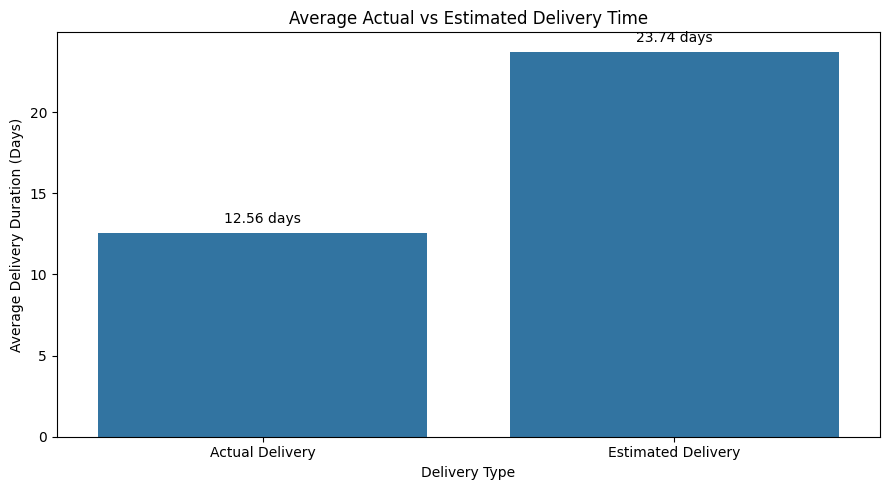

In [57]:
# WEEK 3 - STEP 2: ACTUAL VS ESTIMATED DELIVERY

import matplotlib.pyplot as plt
import seaborn as sns

# Prepare comparison data
comparison = pd.DataFrame({
    "Delivery Type": [
        "Actual Delivery",
        "Estimated Delivery"
    ],
    "Average Days": [
        delivered["actual_delivery_days"].mean(),
        delivered["estimated_delivery_days"].mean()
    ]
})

# Plot comparison
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=comparison,
    x="Delivery Type",
    y="Average Days"
)

# Add value labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f days", padding=5)

plt.title("Average Actual vs Estimated Delivery Time")
plt.xlabel("Delivery Type")
plt.ylabel("Average Delivery Duration (Days)")
plt.tight_layout()

# Save visualization
plt.savefig(
    FIGURES_DIR / "actual_vs_estimated_delivery.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [58]:
# DELIVERY DELAY DISTRIBUTION

Late Delivery Summary (Days)


count    7826.000000
mean        9.551776
std        13.952540
min         0.002500
25%         1.867179
50%         5.806481
75%        11.820978
max       188.975081
Name: delivery_difference_days, dtype: float64

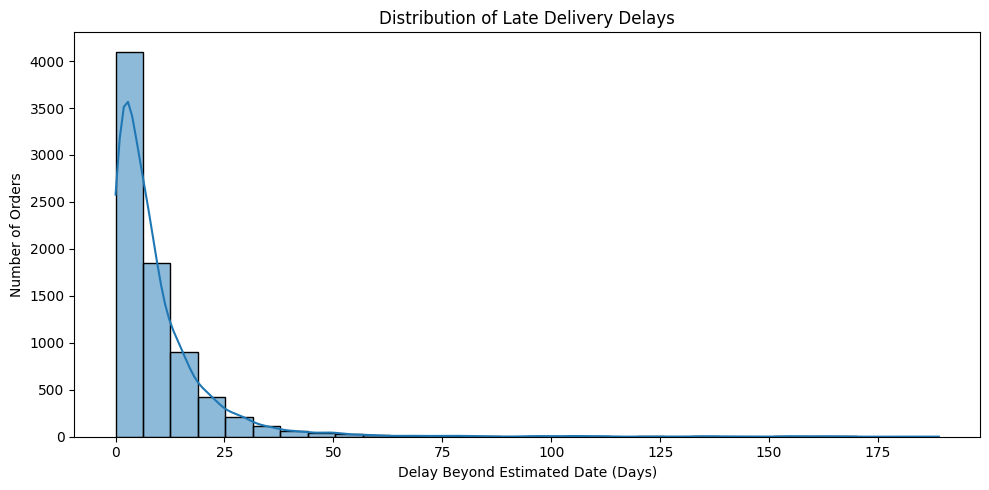

In [59]:
# WEEK 3 - STEP 3: DELIVERY DELAY DISTRIBUTION

import matplotlib.pyplot as plt
import seaborn as sns

# Filter only late deliveries
late_orders = delivered[
    delivered["delivery_difference_days"] > 0
].copy()

# Summary statistics
delay_summary = late_orders["delivery_difference_days"].describe()

print("Late Delivery Summary (Days)")
display(delay_summary)

# Create histogram
plt.figure(figsize=(10, 5))

sns.histplot(
    data=late_orders,
    x="delivery_difference_days",
    bins=30,
    kde=True
)

plt.title("Distribution of Late Delivery Delays")
plt.xlabel("Delay Beyond Estimated Date (Days)")
plt.ylabel("Number of Orders")
plt.tight_layout()

# Save chart
plt.savefig(
    FIGURES_DIR / "delivery_delay_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [60]:
# Monthly Order Trends

,order_month,total_orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


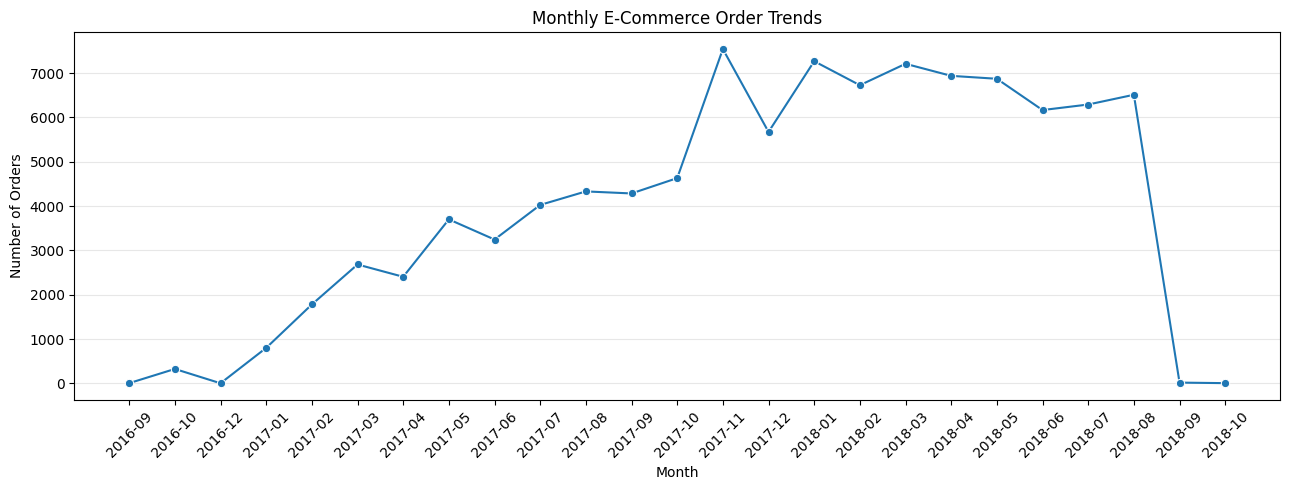

In [61]:
# WEEK 3 - STEP 4: MONTHLY ORDER TRENDS

import matplotlib.pyplot as plt
import seaborn as sns

# Extract month from purchase timestamp
monthly_orders = orders_eda.copy()

monthly_orders["order_month"] = (
    monthly_orders["order_purchase_timestamp"].dt.to_period("M")
)

# Count orders per month
monthly_trend = (
    monthly_orders.groupby("order_month")
    .size()
    .reset_index(name="total_orders")
)

# Convert period to string for plotting
monthly_trend["order_month"] = monthly_trend["order_month"].astype(str)

# Display monthly order counts
display(monthly_trend)

# Plot monthly trend
plt.figure(figsize=(13, 5))

sns.lineplot(
    data=monthly_trend,
    x="order_month",
    y="total_orders",
    marker="o"
)

plt.title("Monthly E-Commerce Order Trends")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    FIGURES_DIR / "monthly_order_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [62]:
# Orders by Day of Week

,order_weekday,total_orders
0,Monday,16196
1,Tuesday,15963
2,Wednesday,15552
3,Thursday,14761
4,Friday,14122
5,Saturday,10887
6,Sunday,11960


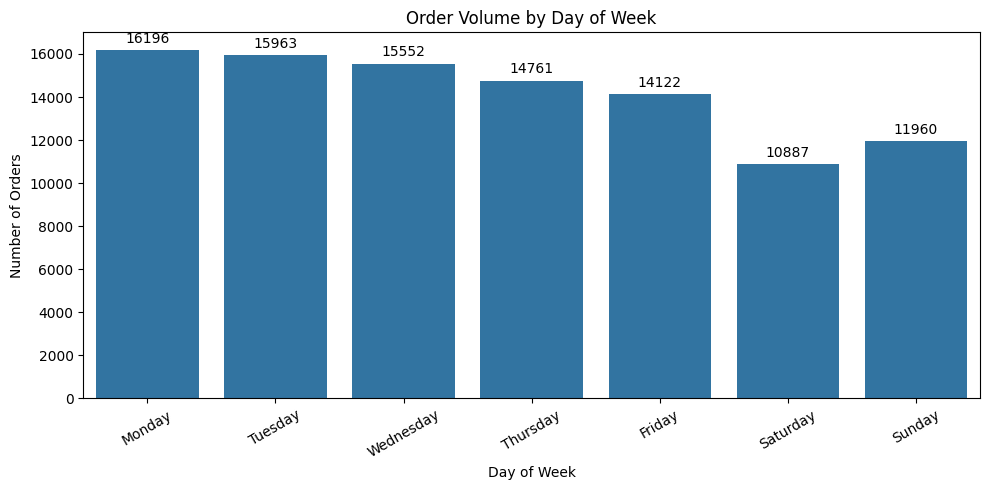

In [63]:
# WEEK 3 - STEP 5: ORDERS BY DAY OF WEEK

import matplotlib.pyplot as plt
import seaborn as sns

# Extract weekday from purchase timestamp
weekday_orders = orders_eda.copy()

weekday_orders["order_weekday"] = (
    weekday_orders["order_purchase_timestamp"].dt.day_name()
)

# Define weekday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Count orders by weekday
weekday_summary = (
    weekday_orders.groupby("order_weekday")
    .size()
    .reindex(weekday_order)
    .reset_index(name="total_orders")
)

display(weekday_summary)

# Plot weekday trend
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=weekday_summary,
    x="order_weekday",
    y="total_orders"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.title("Order Volume by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30)
plt.tight_layout()

# Save chart
plt.savefig(
    FIGURES_DIR / "orders_by_weekday.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [64]:
# Hourly Order Distribution

,purchase_hour,total_orders
0,0,2394
1,1,1170
2,2,510
3,3,272
4,4,206
5,5,188
6,6,502
7,7,1231
8,8,2967
9,9,4785


Busiest hour: 16 | Orders: 6675
Quietest hour: 5 | Orders: 188


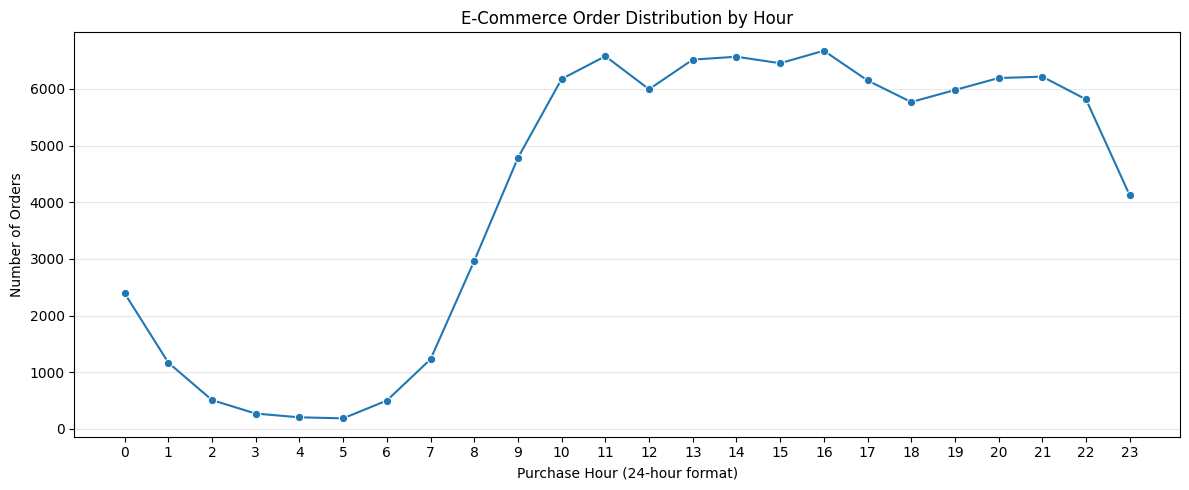

In [65]:
# WEEK 3 - STEP 6: HOURLY ORDER DISTRIBUTION

import matplotlib.pyplot as plt
import seaborn as sns

# Extract purchase hour
hourly_orders = orders_eda.copy()

hourly_orders["purchase_hour"] = (
    hourly_orders["order_purchase_timestamp"].dt.hour
)

# Count orders by hour
hourly_summary = (
    hourly_orders.groupby("purchase_hour")
    .size()
    .reindex(range(24), fill_value=0)
    .reset_index(name="total_orders")
)

display(hourly_summary)

# Find busiest and quietest hours
busiest_hour = hourly_summary.loc[
    hourly_summary["total_orders"].idxmax()
]

quietest_hour = hourly_summary.loc[
    hourly_summary["total_orders"].idxmin()
]

print("Busiest hour:", int(busiest_hour["purchase_hour"]),
      "| Orders:", int(busiest_hour["total_orders"]))

print("Quietest hour:", int(quietest_hour["purchase_hour"]),
      "| Orders:", int(quietest_hour["total_orders"]))

# Create line chart
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly_summary,
    x="purchase_hour",
    y="total_orders",
    marker="o"
)

plt.title("E-Commerce Order Distribution by Hour")
plt.xlabel("Purchase Hour (24-hour format)")
plt.ylabel("Number of Orders")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    FIGURES_DIR / "hourly_order_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [66]:
# Freight Cost Analysis

Freight Cost Summary


count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64


Additional Freight KPIs
Total freight value: 2251909.54
Average freight value: 19.99
Median freight value: 16.26
Zero freight records: 383


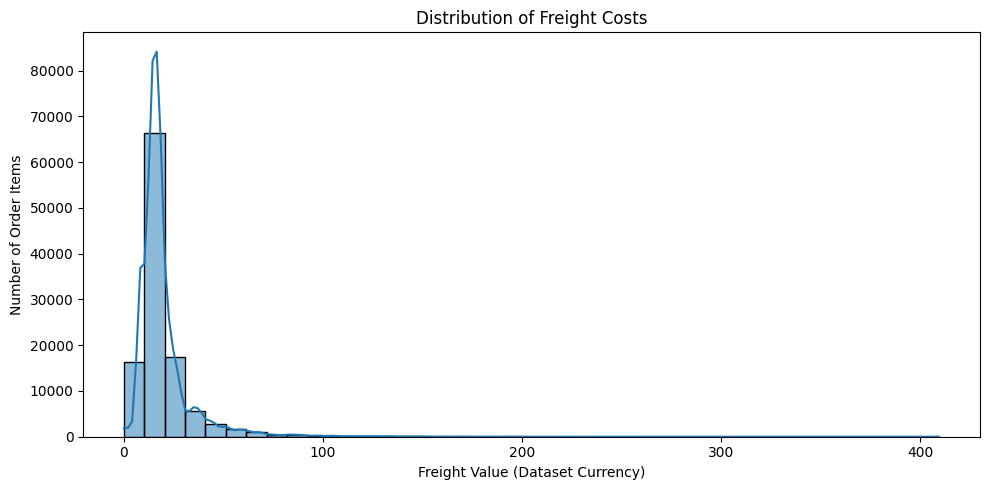

In [67]:
# WEEK 3 - STEP 7: FREIGHT COST ANALYSIS

import matplotlib.pyplot as plt
import seaborn as sns

# Work with original order-item values
freight_eda = order_items.copy()

# Calculate freight cost statistics
freight_summary = freight_eda["freight_value"].describe()

print("Freight Cost Summary")
display(freight_summary)

# Additional freight KPIs
print("\nAdditional Freight KPIs")
print("Total freight value:",
      round(freight_eda["freight_value"].sum(), 2))

print("Average freight value:",
      round(freight_eda["freight_value"].mean(), 2))

print("Median freight value:",
      round(freight_eda["freight_value"].median(), 2))

print("Zero freight records:",
      int((freight_eda["freight_value"] == 0).sum()))

# Create distribution chart
plt.figure(figsize=(10, 5))

sns.histplot(
    data=freight_eda,
    x="freight_value",
    bins=40,
    kde=True
)

plt.title("Distribution of Freight Costs")
plt.xlabel("Freight Value (Dataset Currency)")
plt.ylabel("Number of Order Items")
plt.tight_layout()

# Save chart
plt.savefig(
    FIGURES_DIR / "freight_cost_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [68]:
# Analyze relationship between product price and freight cost

Price vs Freight Correlation


,price,freight_value
price,1.000000,0.414204
freight_value,0.414204,1.000000


Correlation coefficient: 0.414


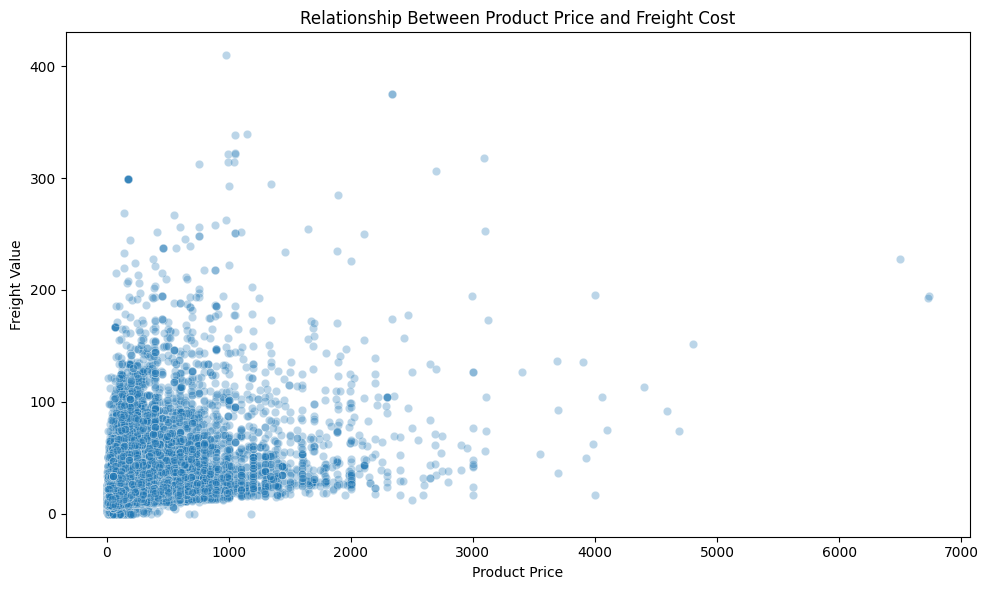

In [69]:
# WEEK 3 - STEP 8: PRICE VS FREIGHT RELATIONSHIP

# Calculate correlation
price_freight_corr = freight_eda[["price", "freight_value"]].corr()

print("Price vs Freight Correlation")
display(price_freight_corr)

correlation_value = price_freight_corr.loc["price", "freight_value"]

print("Correlation coefficient:", round(correlation_value, 3))

# Scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=freight_eda,
    x="price",
    y="freight_value",
    alpha=0.3
)

plt.title("Relationship Between Product Price and Freight Cost")
plt.xlabel("Product Price")
plt.ylabel("Freight Value")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "price_vs_freight_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [70]:
# Regional delivery performance analysis

Top 10 States by Order Volume


,total_orders
customer_state,
SP,41746
RJ,12852
MG,11635
RS,5466
PR,5045
SC,3637
BA,3380
DF,2140
ES,2033



Total customer states: 27


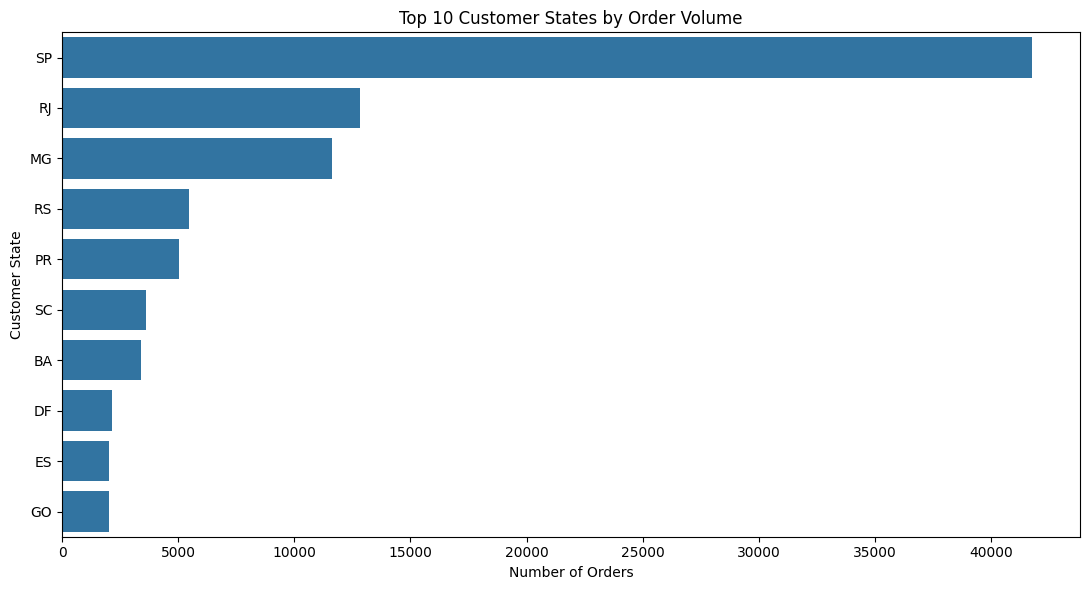

In [71]:
# WEEK 3 - STEP 9: REGIONAL ORDER ANALYSIS

# Merge orders with customer location
regional_orders = orders.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

# Count orders by customer state
state_orders = (
    regional_orders.groupby("customer_state")["order_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 States by Order Volume")
display(state_orders.head(10).to_frame(name="total_orders"))

print("\nTotal customer states:", regional_orders["customer_state"].nunique())

# Plot top 10 states
plt.figure(figsize=(11, 6))

sns.barplot(
    x=state_orders.head(10).values,
    y=state_orders.head(10).index
)

plt.title("Top 10 Customer States by Order Volume")
plt.xlabel("Number of Orders")
plt.ylabel("Customer State")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_10_customer_states.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [72]:
# State-Wise DELIVERY PERFORMANCE

In [73]:
# WEEK 3 - STEP 10: STATE-WISE DELIVERY PERFORMANCE

# Add customer state to delivered orders
state_delivery = delivered.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

# Calculate total and late orders by state
state_performance = (
    state_delivery.groupby("customer_state")
    .agg(
        total_delivered_orders=("order_id", "nunique"),
        late_orders=("delivery_performance",
                     lambda x: (x == "Late").sum())
    )
)

# Calculate late delivery percentage
state_performance["late_delivery_rate"] = (
    state_performance["late_orders"] /
    state_performance["total_delivered_orders"] * 100
)

# Sort by delivered order volume
state_performance = state_performance.sort_values(
    "total_delivered_orders",
    ascending=False
)

print("Top 10 States: Delivery Performance")
display(
    state_performance.head(10).round(2)
)

print("\nHighest Late Delivery Rate (minimum 100 delivered orders)")
display(
    state_performance[
        state_performance["total_delivered_orders"] >= 100
    ]
    .sort_values("late_delivery_rate", ascending=False)
    .head(10)
    .round(2)
)

Top 10 States: Delivery Performance


,total_delivered_orders,late_orders,late_delivery_rate
customer_state,,,
SP,40494,2387,5.89
RJ,12350,1664,13.47
MG,11354,637,5.61
RS,5344,382,7.15
PR,4923,246,5.00
SC,3546,346,9.76
BA,3256,457,14.04
DF,2080,147,7.07
ES,1995,244,12.23



Highest Late Delivery Rate (minimum 100 delivered orders)


,total_delivered_orders,late_orders,late_delivery_rate
customer_state,,,
AL,397,95,23.93
MA,717,141,19.67
PI,476,76,15.97
CE,1279,196,15.32
SE,335,51,15.22
BA,3256,457,14.04
RJ,12350,1664,13.47
TO,274,35,12.77
PA,946,117,12.37


In [74]:
# State-wise late-delivery rate

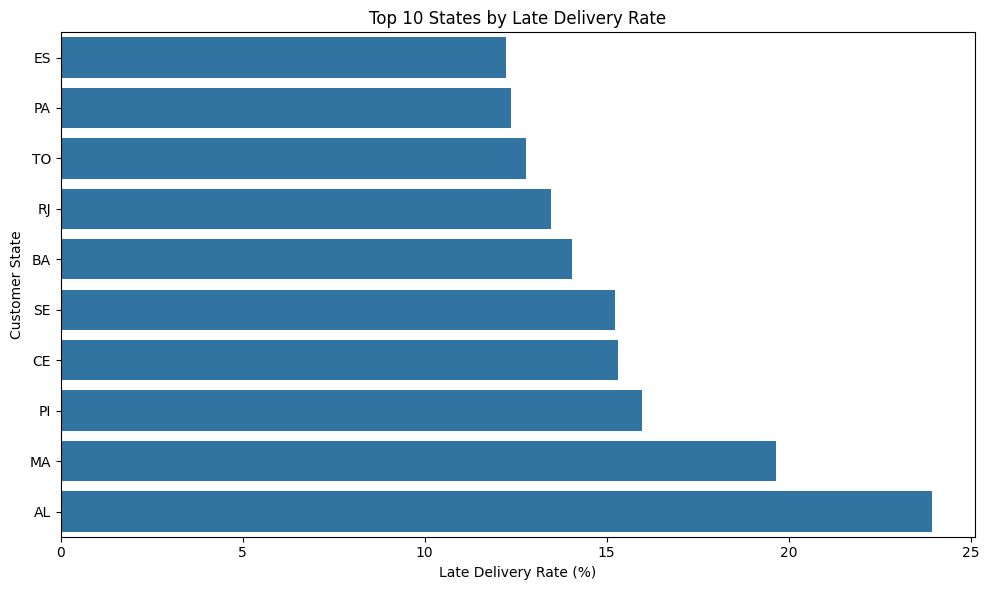

In [75]:
# WEEK 3 - STEP 11: HIGHEST LATE-DELIVERY RATE BY STATE

top_late_states = (
    state_performance[
        state_performance["total_delivered_orders"] >= 100
    ]
    .sort_values("late_delivery_rate", ascending=False)
    .head(10)
    .sort_values("late_delivery_rate", ascending=True)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_late_states.reset_index(),
    x="late_delivery_rate",
    y="customer_state"
)

plt.title("Top 10 States by Late Delivery Rate")
plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Customer State")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "state_wise_late_delivery_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [76]:
# Product category data

In [77]:
# WEEK 3 - STEP 12: PRODUCT CATEGORY ANALYSIS

# Merge order items with product information
category_data = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# Add English category names
category_data = category_data.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

# Replace missing category names
category_data["product_category_name_english"] = (
    category_data["product_category_name_english"]
    .fillna("Unknown")
)

# Calculate category-wise performance
category_summary = (
    category_data.groupby("product_category_name_english")
    .agg(
        total_items=("order_item_id", "count"),
        total_revenue=("price", "sum"),
        average_price=("price", "mean")
    )
    .sort_values("total_items", ascending=False)
)

print("Top 15 Product Categories by Order Items")
display(category_summary.head(15).round(2))

print("\nTotal Product Categories:",
      category_summary.shape[0])

print("\nTotal Order Items:",
      category_summary["total_items"].sum())

Top 15 Product Categories by Order Items


,total_items,total_revenue,average_price
product_category_name_english,,,
bed_bath_table,11115,1036988.68,93.30
health_beauty,9670,1258681.34,130.16
sports_leisure,8641,988048.97,114.34
furniture_decor,8334,729762.49,87.56
computers_accessories,7827,911954.32,116.51
housewares,6964,632248.66,90.79
watches_gifts,5991,1205005.68,201.14
telephony,4545,323667.53,71.21
garden_tools,4347,485256.46,111.63



Total Product Categories: 72

Total Order Items: 112650


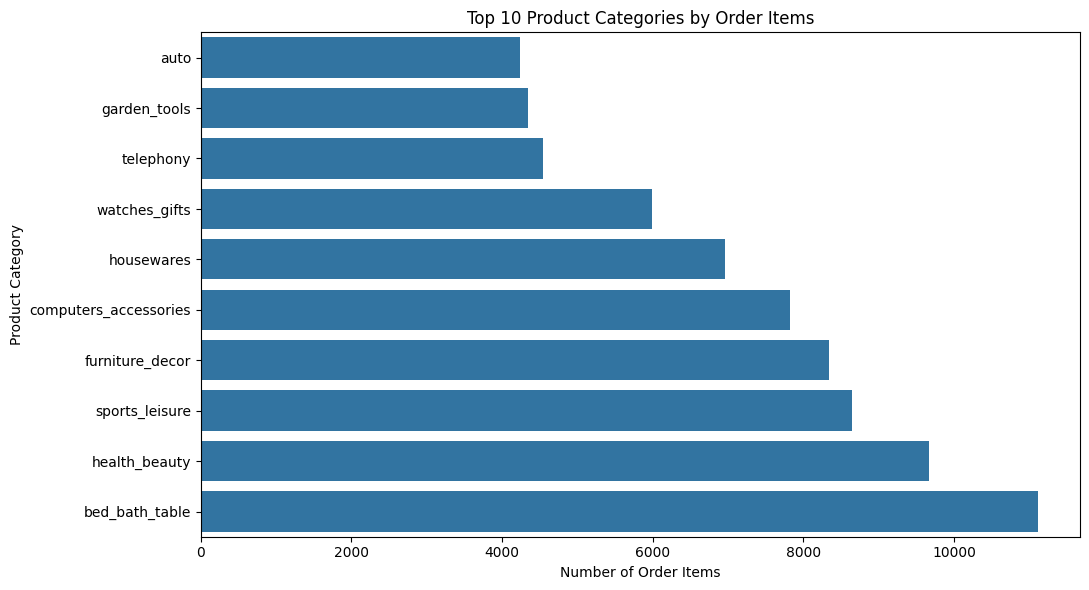

In [78]:
# # WEEK 3 - STEP 13: TOP 10 PRODUCT CATEGORIES

top_categories = (
    category_summary
    .head(10)
    .sort_values("total_items", ascending=True)
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_categories.reset_index(),
    x="total_items",
    y="product_category_name_english"
)

plt.title("Top 10 Product Categories by Order Items")
plt.xlabel("Number of Order Items")
plt.ylabel("Product Category")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_10_product_categories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [79]:
# Top 10 categories by revenue

In [80]:
# WEEK 3 - STEP 14: REVENUE VS ITEM VOLUME

# Select top 10 categories by revenue
top_revenue_categories = (
    category_summary
    .sort_values("total_revenue", ascending=False)
    .head(10)
    .copy()
)

# Display comparison
print("Top 10 Revenue-Generating Categories")

display(
    top_revenue_categories[
        ["total_items", "total_revenue", "average_price"]
    ].round(2)
)

# Compare category revenue and item volume
comparison = top_revenue_categories[
    ["total_items", "total_revenue"]
].copy()

comparison["revenue_rank"] = (
    comparison["total_revenue"].rank(
        ascending=False, method="min"
    ).astype(int)
)

comparison["item_volume_rank"] = (
    comparison["total_items"].rank(
        ascending=False, method="min"
    ).astype(int)
)

comparison["rank_difference"] = (
    comparison["item_volume_rank"] -
    comparison["revenue_rank"]
)

print("\nRevenue Rank vs Item Volume Rank")
display(comparison.sort_values("revenue_rank"))

Top 10 Revenue-Generating Categories


,total_items,total_revenue,average_price
product_category_name_english,,,
health_beauty,9670,1258681.34,130.16
watches_gifts,5991,1205005.68,201.14
bed_bath_table,11115,1036988.68,93.30
sports_leisure,8641,988048.97,114.34
computers_accessories,7827,911954.32,116.51
furniture_decor,8334,729762.49,87.56
cool_stuff,3796,635290.85,167.36
housewares,6964,632248.66,90.79
auto,4235,592720.11,139.96



Revenue Rank vs Item Volume Rank


,total_items,total_revenue,revenue_rank,item_volume_rank,rank_difference
product_category_name_english,,,,,
health_beauty,9670,1258681.34,1,2,1
watches_gifts,5991,1205005.68,2,7,5
bed_bath_table,11115,1036988.68,3,1,-2
sports_leisure,8641,988048.97,4,3,-1
computers_accessories,7827,911954.32,5,5,0
furniture_decor,8334,729762.49,6,4,-2
cool_stuff,3796,635290.85,7,10,3
housewares,6964,632248.66,8,6,-2
auto,4235,592720.11,9,9,0


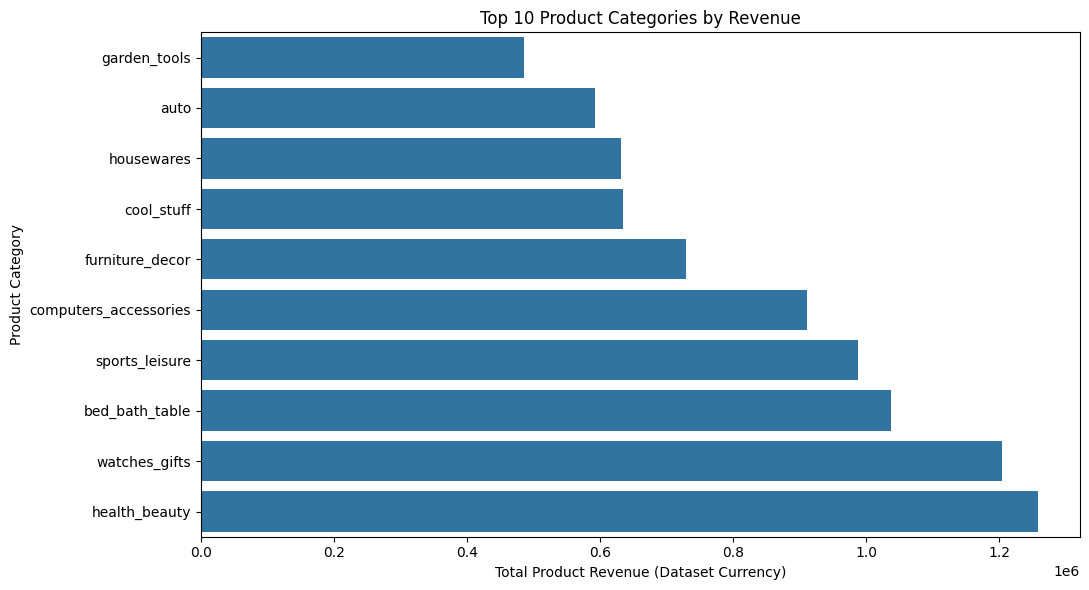

In [81]:
# WEEK 3 - STEP 15: TOP 10 CATEGORIES BY REVENUE

revenue_chart_data = (
    top_revenue_categories
    .sort_values("total_revenue", ascending=True)
    .reset_index()
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=revenue_chart_data,
    x="total_revenue",
    y="product_category_name_english"
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Total Product Revenue (Dataset Currency)")
plt.ylabel("Product Category")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_10_categories_by_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [82]:
# Seller performance analysis

In [83]:
# WEEK 3 - STEP 16: SELLER PERFORMANCE ANALYSIS

# Aggregate order-item data by seller
seller_summary = (
    order_items.groupby("seller_id")
    .agg(
        total_items=("order_item_id", "count"),
        total_revenue=("price", "sum"),
        average_price=("price", "mean"),
        unique_orders=("order_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
)

print("Top 10 Sellers by Product Revenue")

display(
    seller_summary.head(10).round(2)
)

print("\nTotal Active Sellers:",
      order_items["seller_id"].nunique())

print("\nTotal Order Items:",
      seller_summary["total_items"].sum())

Top 10 Sellers by Product Revenue


,total_items,total_revenue,average_price,unique_orders
seller_id,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,1156,229472.63,198.51,1132
53243585a1d6dc2643021fd1853d8905,410,222776.05,543.36,358
4a3ca9315b744ce9f8e9374361493884,1987,200472.92,100.89,1806
fa1c13f2614d7b5c4749cbc52fecda94,586,194042.03,331.13,585
7c67e1448b00f6e969d365cea6b010ab,1364,187923.89,137.77,982
7e93a43ef30c4f03f38b393420bc753a,340,176431.87,518.92,336
da8622b14eb17ae2831f4ac5b9dab84a,1551,160236.57,103.31,1314
7a67c85e85bb2ce8582c35f2203ad736,1171,141745.53,121.05,1160
1025f0e2d44d7041d6cf58b6550e0bfa,1428,138968.55,97.32,915



Total Active Sellers: 3095

Total Order Items: 112650


In [84]:
# WEEK 3 - STEP 17: SELLER REVENUE CONTRIBUTION

# Overall seller performance
total_seller_revenue = order_items["price"].sum()
total_seller_items = len(order_items)
total_unique_orders = order_items["order_id"].nunique()

# Top 10 seller contribution
top_10_revenue = seller_summary.head(10)["total_revenue"].sum()
top_10_items = seller_summary.head(10)["total_items"].sum()
top_10_orders = seller_summary.head(10)["unique_orders"].sum()

# Calculate contribution percentages
revenue_contribution = (
    top_10_revenue / total_seller_revenue
) * 100

item_contribution = (
    top_10_items / total_seller_items
) * 100

order_contribution = (
    top_10_orders / total_unique_orders
) * 100

print("OVERALL MARKETPLACE PERFORMANCE")
print("Total product revenue:", round(total_seller_revenue, 2))
print("Total order items:", total_seller_items)
print("Total unique orders:", total_unique_orders)

print("\nTOP 10 SELLER CONTRIBUTION")
print("Top 10 revenue:", round(top_10_revenue, 2))
print("Revenue contribution (%):", round(revenue_contribution, 2))
print("Item contribution (%):", round(item_contribution, 2))
print("Sum of seller-level unique orders:", top_10_orders)
print("Seller-level order contribution (%):", round(order_contribution, 2))

OVERALL MARKETPLACE PERFORMANCE
Total product revenue: 13591643.7
Total order items: 112650
Total unique orders: 98666

TOP 10 SELLER CONTRIBUTION
Top 10 revenue: 1787241.74
Revenue contribution (%): 13.15
Item contribution (%): 10.2
Sum of seller-level unique orders: 9875
Seller-level order contribution (%): 10.01


In [85]:
# WEEK 3 - STEP 18: SELLER REVENUE CONCENTRATION

# Sort all sellers by revenue
seller_revenue_ranked = seller_summary.sort_values(
    "total_revenue",
    ascending=False
).copy()

total_revenue = seller_revenue_ranked["total_revenue"].sum()

# Calculate cumulative revenue contribution
seller_revenue_ranked["cumulative_revenue"] = (
    seller_revenue_ranked["total_revenue"].cumsum()
)

seller_revenue_ranked["cumulative_revenue_pct"] = (
    seller_revenue_ranked["cumulative_revenue"] /
    total_revenue * 100
)

# Calculate contribution for selected seller groups
seller_groups = [1, 5, 10, 20, 50]

concentration_results = []

for n in seller_groups:
    revenue = seller_revenue_ranked.head(n)["total_revenue"].sum()

    concentration_results.append({
        "top_sellers": n,
        "total_revenue": round(revenue, 2),
        "revenue_contribution_pct": round(
            revenue / total_revenue * 100, 2
        )
    })

concentration_df = pd.DataFrame(concentration_results)

print("Seller Revenue Concentration")
display(concentration_df)

print("\nTop 10 Sellers Cumulative Revenue Share:",
      round(
          seller_revenue_ranked.head(10)
          ["cumulative_revenue_pct"].iloc[-1], 2
      ), "%")

Seller Revenue Concentration


,top_sellers,total_revenue,revenue_contribution_pct
0,1,229472.63,1.69
1,5,1034687.52,7.61
2,10,1787241.74,13.15
3,20,2866544.30,21.09
4,50,4470124.17,32.89



Top 10 Sellers Cumulative Revenue Share: 13.15 %


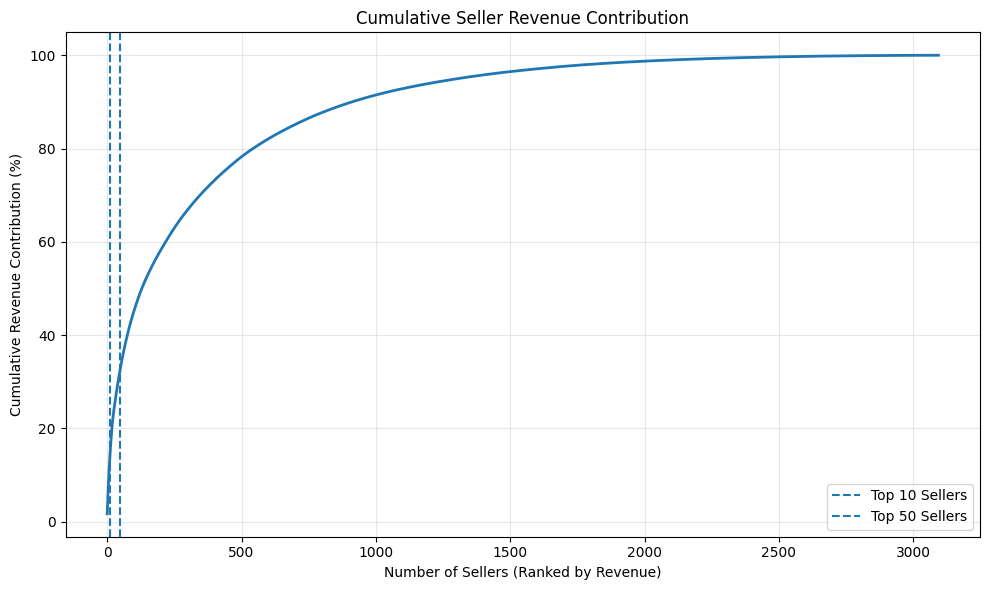

In [86]:
# WEEK 3 - STEP 19: SELLER REVENUE CONCENTRATION CHART

plt.figure(figsize=(10, 6))

plt.plot(
    seller_revenue_ranked["cumulative_revenue_pct"].values,
    linewidth=2
)

plt.axvline(
    x=9,
    linestyle="--",
    label="Top 10 Sellers"
)

plt.axvline(
    x=49,
    linestyle="--",
    label="Top 50 Sellers"
)

plt.title("Cumulative Seller Revenue Contribution")
plt.xlabel("Number of Sellers (Ranked by Revenue)")
plt.ylabel("Cumulative Revenue Contribution (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "seller_revenue_concentration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [87]:
# Seller Delivery Performace

In [88]:
# WEEK 3 - STEP 20: SELLER DELIVERY PERFORMANCE

# Connect delivered orders with their sellers
seller_delivery = delivered[
    ["order_id", "delivery_performance", "delivery_difference_days"]
].merge(
    order_items[["order_id", "seller_id", "order_item_id"]],
    on="order_id",
    how="inner"
)

# Calculate seller-level delivery performance
seller_delivery_summary = (
    seller_delivery.groupby("seller_id")
    .agg(
        total_items=("order_item_id", "count"),
        total_orders=("order_id", "nunique"),
        late_items=("delivery_performance",
                    lambda x: (x == "Late").sum()),
        average_delivery_delay=("delivery_difference_days", "mean")
    )
)

# Calculate late-delivery rate at item level
seller_delivery_summary["late_delivery_rate"] = (
    seller_delivery_summary["late_items"] /
    seller_delivery_summary["total_items"] * 100
)

# Merge seller revenue information
seller_delivery_summary = seller_delivery_summary.merge(
    seller_summary[["total_revenue", "average_price"]],
    left_index=True,
    right_index=True,
    how="left"
)

# Display top 10 revenue-generating sellers
top_seller_delivery = (
    seller_delivery_summary
    .sort_values("total_revenue", ascending=False)
    .head(10)
)

print("Delivery Performance of Top 10 Revenue Sellers")

display(top_seller_delivery.round(2))

Delivery Performance of Top 10 Revenue Sellers


,total_items,total_orders,late_items,average_delivery_delay,late_delivery_rate,total_revenue,average_price
seller_id,,,,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,1148,1124,133,-10.45,11.59,229472.63,198.51
53243585a1d6dc2643021fd1853d8905,400,348,16,-10.88,4.00,222776.05,543.36
4a3ca9315b744ce9f8e9374361493884,1949,1772,214,-8.95,10.98,200472.92,100.89
fa1c13f2614d7b5c4749cbc52fecda94,579,578,59,-9.61,10.19,194042.03,331.13
7c67e1448b00f6e969d365cea6b010ab,1355,973,130,-10.83,9.59,187923.89,137.77
7e93a43ef30c4f03f38b393420bc753a,322,319,18,-11.49,5.59,176431.87,518.92
da8622b14eb17ae2831f4ac5b9dab84a,1548,1311,113,-10.53,7.30,160236.57,103.31
7a67c85e85bb2ce8582c35f2203ad736,1155,1145,68,-11.16,5.89,141745.53,121.05
1025f0e2d44d7041d6cf58b6550e0bfa,1420,910,131,-10.39,9.23,138968.55,97.32


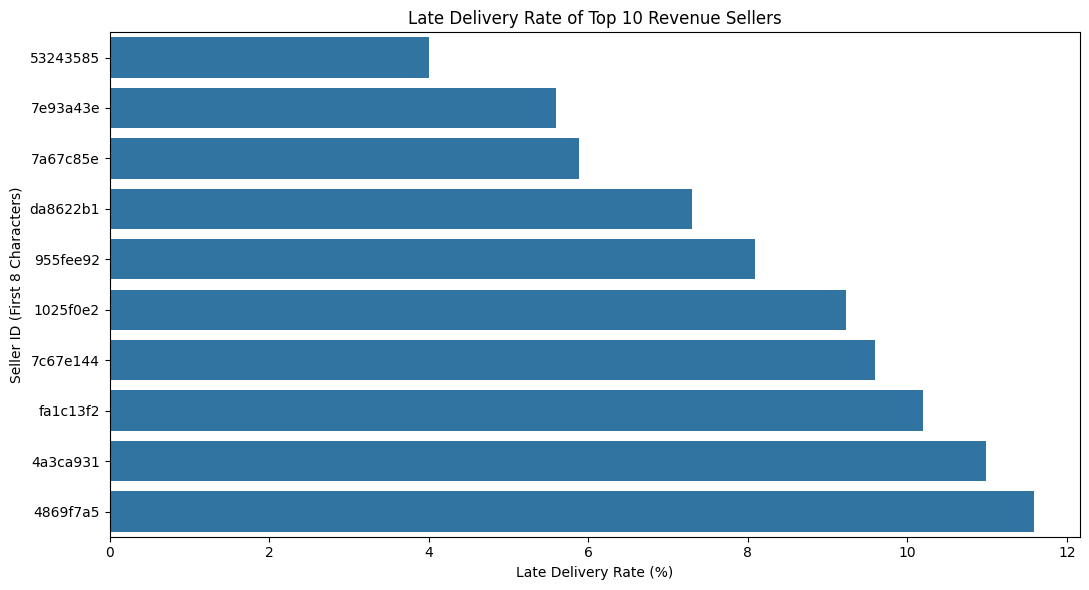

In [89]:
# WEEK 3 - STEP 21: SELLER LATE DELIVERY RATE CHART

seller_chart = (
    top_seller_delivery
    .sort_values("late_delivery_rate", ascending=True)
    .reset_index()
)

seller_chart["seller_short_id"] = (
    seller_chart["seller_id"].str[:8]
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=seller_chart,
    x="late_delivery_rate",
    y="seller_short_id"
)

plt.title("Late Delivery Rate of Top 10 Revenue Sellers")
plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Seller ID (First 8 Characters)")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_sellers_late_delivery_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [90]:
# Delivery Performance and Review Score

In [91]:
# Merge delivery performance with customer reviews
delivery_reviews = delivered[
    ["order_id", "delivery_performance", "delivery_difference_days"]
].merge(
    reviews[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

# Compare review scores for early and late deliveries
review_comparison = (
    delivery_reviews
    .groupby("delivery_performance")
    .agg(
        total_reviews=("review_score", "count"),
        average_review_score=("review_score", "mean"),
        median_review_score=("review_score", "median")
    )
    .round(2)
    .reset_index()
)

print("Delivery Performance vs Customer Review Scores")
display(review_comparison)

Delivery Performance vs Customer Review Scores


,delivery_performance,total_reviews,average_review_score,median_review_score
0,Early,88653,4.29,5.0
1,Late,7700,2.57,2.0


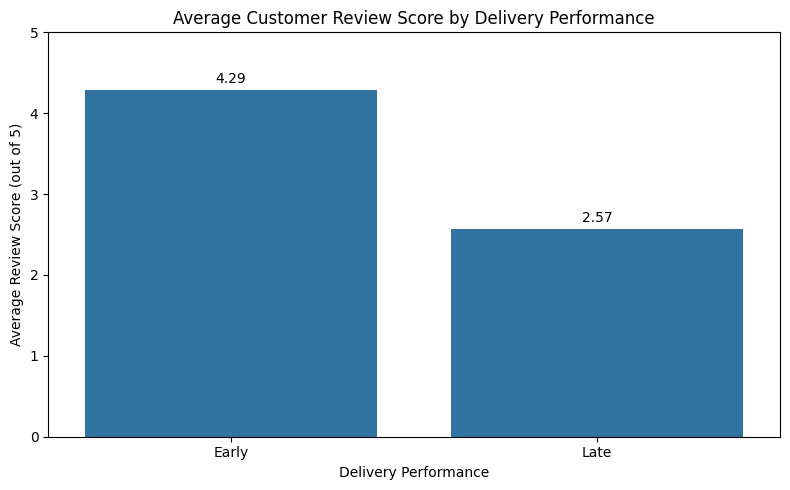

In [92]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=review_comparison,
    x="delivery_performance",
    y="average_review_score"
)

plt.title("Average Customer Review Score by Delivery Performance")
plt.xlabel("Delivery Performance")
plt.ylabel("Average Review Score (out of 5)")
plt.ylim(0, 5)

for index, value in enumerate(review_comparison["average_review_score"]):
    plt.text(index, value + 0.08, f"{value:.2f}", ha="center")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "review_score_by_delivery_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [93]:
# Aggregate order items at order level
order_level_items = (
    order_items
    .groupby("order_id")
    .agg(
        order_item_count=("order_item_id", "count"),
        product_revenue=("price", "sum"),
        freight_total=("freight_value", "sum")
    )
    .reset_index()
)

# Aggregate payments at order level
order_level_payments = (
    payments
    .groupby("order_id")
    .agg(
        payment_total=("payment_value", "sum")
    )
    .reset_index()
)

# Merge both aggregated datasets
order_level_analysis = order_level_items.merge(
    order_level_payments,
    on="order_id",
    how="inner"
)

print("Order-level dataset shape:", order_level_analysis.shape)
display(order_level_analysis.head())

print("\nCorrelation matrix:")
display(
    order_level_analysis[
        ["order_item_count", "product_revenue", "freight_total", "payment_total"]
    ].corr().round(3)
)

Order-level dataset shape: (98665, 5)


,order_id,order_item_count,product_revenue,freight_total,payment_total
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,72.19
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,259.83
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,216.87
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,218.04



Correlation matrix:


,order_item_count,product_revenue,freight_total,payment_total
order_item_count,1.000,0.153,0.437,0.189
product_revenue,0.153,1.000,0.413,0.996
freight_total,0.437,0.413,1.000,0.493
payment_total,0.189,0.996,0.493,1.000


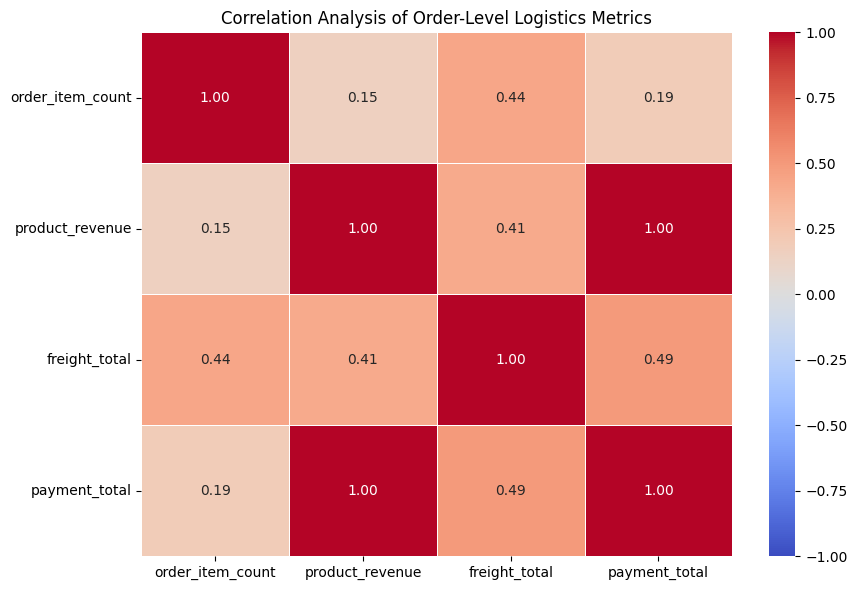

In [94]:
# Select numerical variables
correlation_data = order_level_analysis[
    [
        "order_item_count",
        "product_revenue",
        "freight_total",
        "payment_total"
    ]
]

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

# Generate heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Analysis of Order-Level Logistics Metrics")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "order_level_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [95]:
# Overall customer review-score distribution

Overall Review Score Distribution


,review_score,review_count,percentage
0,1,11424,11.51
1,2,3151,3.18
2,3,8179,8.24
3,4,19142,19.29
4,5,57328,57.78



Average review score: 4.09
Median review score: 5.0
Total reviews: 99224


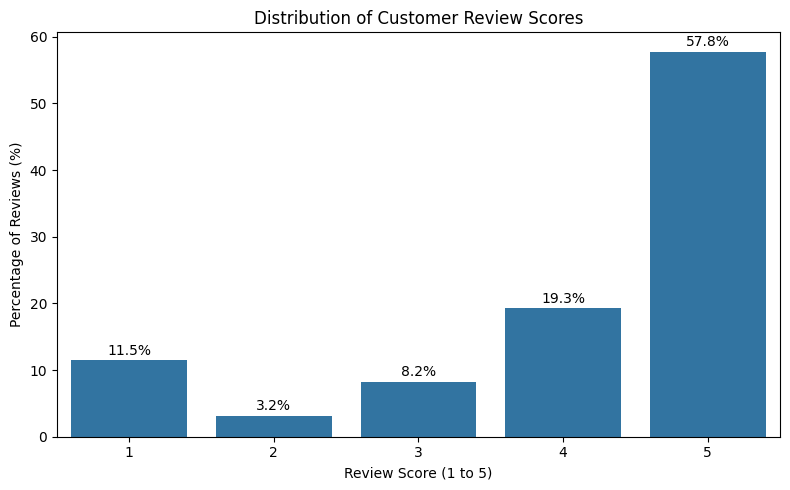

In [96]:
# Analyse overall customer review scores
review_score_summary = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
    .reset_index()
)

review_score_summary.columns = ["review_score", "review_count"]

review_score_summary["percentage"] = (
    review_score_summary["review_count"] /
    review_score_summary["review_count"].sum() * 100
).round(2)

print("Overall Review Score Distribution")
display(review_score_summary)

print("\nAverage review score:", round(reviews["review_score"].mean(), 2))
print("Median review score:", reviews["review_score"].median())
print("Total reviews:", len(reviews))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=review_score_summary,
    x="review_score",
    y="percentage"
)

plt.title("Distribution of Customer Review Scores")
plt.xlabel("Review Score (1 to 5)")
plt.ylabel("Percentage of Reviews (%)")

for index, value in enumerate(review_score_summary["percentage"]):
    plt.text(index, value + 0.8, f"{value:.1f}%", ha="center")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "overall_review_score_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [97]:
final_eda_summary = pd.DataFrame({
    "Metric": [
        "Total orders",
        "Total order items",
        "Total delivered orders analysed",
        "Late delivery rate (%)",
        "Average actual delivery time (days)",
        "Median actual delivery time (days)",
        "Average freight per order item",
        "Total product revenue",
        "Total freight value",
        "Average customer review score",
        "Late delivery average review score",
        "Early delivery average review score"
    ],
    "Value": [
        len(orders),
        len(order_items),
        len(delivered),
        round((delivered["delivery_performance"] == "Late").mean() * 100, 2),
        round(delivered["actual_delivery_days"].mean(), 2),
        round(delivered["actual_delivery_days"].median(), 2),
        round(order_items["freight_value"].mean(), 2),
        round(order_items["price"].sum(), 2),
        round(order_items["freight_value"].sum(), 2),
        round(reviews["review_score"].mean(), 2),
        round(review_comparison.loc[
            review_comparison["delivery_performance"] == "Late",
            "average_review_score"
        ].iloc[0], 2),
        round(review_comparison.loc[
            review_comparison["delivery_performance"] == "Early",
            "average_review_score"
        ].iloc[0], 2)
    ]
})

display(final_eda_summary)

,Metric,Value
0,Total orders,99441.00
1,Total order items,112650.00
2,Total delivered orders analysed,96470.00
3,Late delivery rate (%),8.11
4,Average actual delivery time (days),12.56
5,Median actual delivery time (days),10.22
6,Average freight per order item,19.99
7,Total product revenue,13591643.70
8,Total freight value,2251909.54
9,Average customer review score,4.09


In [98]:
# Check main project deliverables
required_files = [
    PROJECT_DIR / "Logistics_Data_Analytics.ipynb",
    PROJECT_DIR / "Logistics_Data_Analytics.py",
    PROCESSED_DIR / "orders_clean.csv",
    PROCESSED_DIR / "order_items_clean.csv",
    PROCESSED_DIR / "customers_clean.csv",
    PROCESSED_DIR / "payments_clean.csv",
    PROCESSED_DIR / "reviews_clean.csv",
    PROCESSED_DIR / "products_clean.csv",
    PROCESSED_DIR / "sellers_clean.csv",
    PROCESSED_DIR / "geolocation_clean.csv",
    PROCESSED_DIR / "category_translation_clean.csv",
    PROCESSED_DIR / "order_items_scaled.csv"
]

file_validation = pd.DataFrame({
    "file": [str(path.relative_to(PROJECT_DIR)) for path in required_files],
    "status": ["Available" if path.exists() else "Missing"
               for path in required_files]
})

display(file_validation)

print("\nTotal files checked:", len(required_files))
print("Available:", (file_validation["status"] == "Available").sum())
print("Missing:", (file_validation["status"] == "Missing").sum())

# Check Python script size
script_path = PROJECT_DIR / "Logistics_Data_Analytics.py"

if script_path.exists():
    print("\nPython script size:", round(script_path.stat().st_size / 1024, 2), "KB")

,file,status
0,Logistics_Data_Analytics.ipynb,Available
1,Logistics_Data_Analytics.py,Available
2,data\processed\orders_clean.csv,Available
3,data\processed\order_items_clean.csv,Available
4,data\processed\customers_clean.csv,Available
5,data\processed\payments_clean.csv,Available
6,data\processed\reviews_clean.csv,Available
7,data\processed\products_clean.csv,Available
8,data\processed\sellers_clean.csv,Available
9,data\processed\geolocation_clean.csv,Available



Total files checked: 12
Available: 12
Missing: 0

Python script size: 55.52 KB


In [ ]:
# Week 4 – Predictive Modeling and Optimization in Logistics Systems

In [99]:

# Week 4: Predictive Modeling and Optimization
# Step 1: Import libraries and load cleaned datasets

from pathlib import Path
import pandas as pd
import numpy as np

# Machine learning libraries
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Project directory
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data" / "processed"
OUTPUT_DIR = BASE_DIR / "outputs"

# Load cleaned datasets
orders = pd.read_csv(DATA_DIR / "orders_clean.csv")
items = pd.read_csv(DATA_DIR / "order_items_clean.csv")
customers = pd.read_csv(DATA_DIR / "customers_clean.csv")
products = pd.read_csv(DATA_DIR / "products_clean.csv")
sellers = pd.read_csv(DATA_DIR / "sellers_clean.csv")

# Display dataset dimensions
print("Orders:", orders.shape)
print("Order Items:", items.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)
print("Sellers:", sellers.shape)

print("\nAll datasets loaded successfully!")


Orders: (99441, 8)
Order Items: (112650, 7)
Customers: (99441, 5)
Products: (32951, 11)
Sellers: (3095, 4)

All datasets loaded successfully!


In [100]:

# Step 2: Inspect columns and data types

datasets = {
    "Orders": orders,
    "Order Items": items,
    "Customers": customers,
    "Products": products,
    "Sellers": sellers
}

for name, df in datasets.items():
    print(f"\n{'='*60}")
    print(f"{name} - Columns")
    print("="*60)
    print(df.columns.tolist())
    print("\nData types:")
    print(df.dtypes)



Orders - Columns
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Data types:
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

Order Items - Columns
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Data types:
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

Customers - Columns
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'custome

In [ ]:
# Prepare order-level data

In [101]:

# Step 3: Create delivery-time target variable

# Convert order timestamps into datetime format
date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

# Keep only delivered orders with valid purchase and delivery dates
model_orders = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_purchase_timestamp"].notna()) &
    (orders["order_delivered_customer_date"].notna())
].copy()

# Calculate actual delivery time in days
model_orders["delivery_time_days"] = (
    model_orders["order_delivered_customer_date"] -
    model_orders["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Remove invalid negative delivery durations
model_orders = model_orders[
    model_orders["delivery_time_days"] >= 0
].copy()

# Check target variable
print("Total valid delivered orders:", len(model_orders))
print("\nDelivery time statistics:")
print(model_orders["delivery_time_days"].describe().round(2))

print("\nMissing target values:",
      model_orders["delivery_time_days"].isna().sum())


Total valid delivered orders: 96470

Delivery time statistics:
count    96470.00
mean        12.56
std          9.55
min          0.53
25%          6.77
50%         10.22
75%         15.72
max        209.63
Name: delivery_time_days, dtype: float64

Missing target values: 0


In [102]:

# Step 4: Aggregate order-item and product information

# Join order items with product details
items_products = items.merge(
    products,
    on="product_id",
    how="left"
)

# Aggregate product and freight information at order level
order_features = items_products.groupby("order_id").agg(
    item_count=("order_item_id", "count"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    unique_sellers=("seller_id", "nunique"),
    avg_product_weight=("product_weight_g", "mean"),
    avg_product_length=("product_length_cm", "mean"),
    avg_product_height=("product_height_cm", "mean"),
    avg_product_width=("product_width_cm", "mean"),
    unique_categories=("product_category_name", "nunique")
).reset_index()

print("Aggregated order features:", order_features.shape)
print("\nSample records:")
display(order_features.head())

print("\nMissing values:")
print(order_features.isnull().sum())


Aggregated order features: (98666, 10)

Sample records:


,order_id,item_count,total_price,total_freight,unique_sellers,avg_product_weight,avg_product_length,avg_product_height,avg_product_width,unique_categories
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,1,650.0,28.0,9.0,14.0,1
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,1,30000.0,50.0,30.0,40.0,1
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,1,3050.0,33.0,13.0,33.0,1
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,1,200.0,16.0,10.0,15.0,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,1,3750.0,35.0,40.0,30.0,1



Missing values:
order_id               0
item_count             0
total_price            0
total_freight          0
unique_sellers         0
avg_product_weight    16
avg_product_length    16
avg_product_height    16
avg_product_width     16
unique_categories      0
dtype: int64


In [104]:
# Step 5A: Identify the most frequent seller state per order

seller_order_data = items.merge(
    sellers[["seller_id", "seller_state"]],
    on="seller_id",
    how="left"
)

# Select the most frequent seller state for each order
def get_main_seller_state(series):
    modes = series.dropna().mode()
    return modes.iloc[0] if not modes.empty else np.nan

seller_features = (
    seller_order_data.groupby("order_id")["seller_state"]
    .agg(get_main_seller_state)
    .reset_index(name="main_seller_state")
)

# Add customer geographic information
customer_features = customers[
    ["customer_id", "customer_state", "customer_city"]
].copy()

# Combine order-level features with customers
model_data = (
    model_orders.merge(
        order_features,
        on="order_id",
        how="inner"
    )
    .merge(
        customer_features,
        on="customer_id",
        how="left"
    )
    .merge(
        seller_features,
        on="order_id",
        how="left"
    )
)

print("Final merged dataset shape:", model_data.shape)
print("\nSample records:")
display(model_data.head())

print("\nMissing values:")
print(model_data.isnull().sum())


Final merged dataset shape: (96470, 21)

Sample records:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time_days,item_count,...,total_freight,unique_sellers,avg_product_weight,avg_product_length,avg_product_height,avg_product_width,unique_categories,customer_state,customer_city,main_seller_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,1,...,8.72,1,500.0,19.0,8.0,13.0,1,SP,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,1,...,22.76,1,400.0,19.0,13.0,19.0,1,BA,barreiras,SP
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,1,...,19.22,1,420.0,24.0,19.0,21.0,1,GO,vianopolis,SP
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,1,...,27.20,1,450.0,30.0,10.0,20.0,1,RN,sao goncalo do amarante,MG
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,1,...,8.72,1,250.0,51.0,15.0,15.0,1,SP,santo andre,SP



Missing values:
order_id                          0
customer_id                       0
order_status                      0
order_purchase_timestamp          0
order_approved_at                14
order_delivered_carrier_date      1
order_delivered_customer_date     0
order_estimated_delivery_date     0
delivery_time_days                0
item_count                        0
total_price                       0
total_freight                     0
unique_sellers                    0
avg_product_weight               16
avg_product_length               16
avg_product_height               16
avg_product_width                16
unique_categories                 0
customer_state                    0
customer_city                     0
main_seller_state                 0
dtype: int64


In [ ]:
# Target: delivery_time_days

In [105]:

# Step 6: Feature engineering and predictor selection

# Extract purchase-time features
model_data["purchase_month"] = (
    model_data["order_purchase_timestamp"].dt.month
)

model_data["purchase_day_of_week"] = (
    model_data["order_purchase_timestamp"].dt.dayofweek
)

model_data["purchase_hour"] = (
    model_data["order_purchase_timestamp"].dt.hour
)

# Select numerical predictors
numerical_features = [
    "item_count",
    "total_price",
    "total_freight",
    "unique_sellers",
    "avg_product_weight",
    "avg_product_length",
    "avg_product_height",
    "avg_product_width",
    "unique_categories",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour"
]

# Select categorical predictors
categorical_features = [
    "customer_state",
    "main_seller_state"
]

# Create X (independent variables) and y (target)
X = model_data[numerical_features + categorical_features].copy()
y = model_data["delivery_time_days"].copy()

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nMissing values in predictors:")
print(X.isnull().sum())

print("\nTarget summary:")
print(y.describe().round(2))


Feature dataset shape: (96470, 14)
Target dataset shape: (96470,)

Numerical features: 12
Categorical features: 2

Missing values in predictors:
item_count               0
total_price              0
total_freight            0
unique_sellers           0
avg_product_weight      16
avg_product_length      16
avg_product_height      16
avg_product_width       16
unique_categories        0
purchase_month           0
purchase_day_of_week     0
purchase_hour            0
customer_state           0
main_seller_state        0
dtype: int64

Target summary:
count    96470.00
mean        12.56
std          9.55
min          0.53
25%          6.77
50%         10.22
75%         15.72
max        209.63
Name: delivery_time_days, dtype: float64


In [ ]:
# Split training and testing data

In [106]:

# Step 7: Time-based train-test split

# Sort orders chronologically by purchase date
sorted_indices = model_data.sort_values(
    "order_purchase_timestamp"
).index

# Use the first 80% for training and the latest 20% for testing
split_position = int(len(sorted_indices) * 0.80)

train_indices = sorted_indices[:split_position]
test_indices = sorted_indices[split_position:]

X_train = X.loc[train_indices]
X_test = X.loc[test_indices]

y_train = y.loc[train_indices]
y_test = y.loc[test_indices]

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target records:", len(y_train))
print("Testing target records:", len(y_test))

print("\nTraining period:")
print(model_data.loc[train_indices, "order_purchase_timestamp"].min())
print("to")
print(model_data.loc[train_indices, "order_purchase_timestamp"].max())

print("\nTesting period:")
print(model_data.loc[test_indices, "order_purchase_timestamp"].min())
print("to")
print(model_data.loc[test_indices, "order_purchase_timestamp"].max())


Training data shape: (77176, 14)
Testing data shape: (19294, 14)

Training target records: 77176
Testing target records: 19294

Training period:
2016-09-15 12:16:38
to
2018-05-26 18:16:57

Testing period:
2018-05-26 18:18:03
to
2018-08-29 15:00:37


In [ ]:
# Build the preprocessing pipeline

In [107]:

# Step 8: Create preprocessing pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("\nMissing numerical values in training data:")
print(X_train[numerical_features].isnull().sum().sum())


Preprocessing pipeline created successfully!

Numerical features: 12
Categorical features: 2

Missing numerical values in training data:
64


In [ ]:
# Train three-regression models

In [108]:

# Step 9: Train regression models

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_split=20,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}

for name, model in models.items():

    # Create a complete pipeline for each model
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])

    print(f"Training {name}...")

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} training completed!\n")

print("All three models trained successfully!")


Training Linear Regression...
Linear Regression training completed!

Training Decision Tree...
Decision Tree training completed!

Training Random Forest...
Random Forest training completed!

All three models trained successfully!


In [ ]:
# Evaluate model performance

In [109]:

# Step 10: Evaluate all models on test data

results = []

predictions = {}

for name, pipeline in trained_models.items():

    # Generate predictions
    y_pred = pipeline.predict(X_test)
    predictions[name] = y_pred

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Create comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

# Identify best model by MAE
best_model_name = results_df.loc[0, "Model"]

print("\nBest model based on MAE:", best_model_name)


MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2 Score
0,Random Forest,4.4113,5.7968,0.0348
1,Decision Tree,4.5210,5.9663,-0.0225
2,Linear Regression,5.7034,7.0190,-0.4151



Best model based on MAE: Random Forest


In [ ]:
# Compare against a baseline model

In [110]:

# Step 11: Evaluate a simple median baseline

# Calculate median delivery time from training data only
baseline_prediction = y_train.median()

# Predict the same value for every test order
baseline_predictions = np.full(
    len(y_test),
    baseline_prediction
)

# Calculate baseline metrics
baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

# Compare baseline with Random Forest
baseline_comparison = pd.DataFrame({
    "Model": ["Median Baseline", "Random Forest"],
    "MAE": [
        baseline_mae,
        mean_absolute_error(y_test, predictions["Random Forest"])
    ],
    "RMSE": [
        baseline_rmse,
        np.sqrt(mean_squared_error(
            y_test, predictions["Random Forest"]
        ))
    ],
    "R2 Score": [
        baseline_r2,
        r2_score(y_test, predictions["Random Forest"])
    ]
})

print("BASELINE VS RANDOM FOREST")
display(baseline_comparison.round(4))

print("\nTraining median delivery time:",
      round(baseline_prediction, 2), "days")


BASELINE VS RANDOM FOREST


,Model,MAE,RMSE,R2 Score
0,Median Baseline,4.9628,6.3808,-0.1695
1,Random Forest,4.4113,5.7968,0.0348



Training median delivery time: 11.18 days


In [ ]:
# Analyse prediction errors

In [111]:

# Step 12: Analyse Random Forest prediction errors

rf_predictions = predictions["Random Forest"]

error_analysis = pd.DataFrame({
    "Actual_Delivery_Days": y_test.values,
    "Predicted_Delivery_Days": rf_predictions
})

error_analysis["Absolute_Error"] = abs(
    error_analysis["Actual_Delivery_Days"] -
    error_analysis["Predicted_Delivery_Days"]
)

# Group orders by actual delivery duration
error_analysis["Delivery_Group"] = pd.cut(
    error_analysis["Actual_Delivery_Days"],
    bins=[0, 7, 15, 30, np.inf],
    labels=["0-7 days", "7-15 days", "15-30 days", "Above 30 days"]
)

# Calculate error for each group
group_error = error_analysis.groupby(
    "Delivery_Group",
    observed=False
).agg(
    Order_Count=("Actual_Delivery_Days", "count"),
    Average_Actual_Days=("Actual_Delivery_Days", "mean"),
    Average_Predicted_Days=("Predicted_Delivery_Days", "mean"),
    Average_Absolute_Error=("Absolute_Error", "mean")
).reset_index()

print("PREDICTION ERROR BY DELIVERY-TIME GROUP")
display(group_error.round(2))

print("\nOverall prediction error:")
print("MAE:", round(error_analysis["Absolute_Error"].mean(), 2), "days")


PREDICTION ERROR BY DELIVERY-TIME GROUP


,Delivery_Group,Order_Count,Average_Actual_Days,Average_Predicted_Days,Average_Absolute_Error
0,0-7 days,8425,4.57,8.90,4.39
1,7-15 days,8852,9.88,12.75,3.86
2,15-30 days,1834,19.34,15.39,5.08
3,Above 30 days,183,40.85,15.65,25.20



Overall prediction error:
MAE: 4.41 days


In [ ]:
# Time-series cross-validation

In [112]:

# Step 13: Time-series cross-validation

from sklearn.model_selection import TimeSeriesSplit

# Combine training data and preserve chronological order
X_cv = X_train.copy()
y_cv = y_train.copy()

# Time-series cross-validation
tscv = TimeSeriesSplit(n_splits=3)

cv_mae_scores = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_cv), start=1
):
    X_fold_train = X_cv.iloc[train_idx]
    X_fold_val = X_cv.iloc[val_idx]

    y_fold_train = y_cv.iloc[train_idx]
    y_fold_val = y_cv.iloc[val_idx]

    # Build a fresh pipeline for each fold
    rf_cv_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            min_samples_split=20,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ))
    ])

    rf_cv_pipeline.fit(X_fold_train, y_fold_train)

    fold_predictions = rf_cv_pipeline.predict(X_fold_val)

    fold_mae = mean_absolute_error(
        y_fold_val,
        fold_predictions
    )

    cv_mae_scores.append(fold_mae)

    print(f"Fold {fold} MAE: {fold_mae:.4f} days")

print("\nCross-validation summary")
print("Mean MAE:", round(np.mean(cv_mae_scores), 4))
print("Standard deviation:", round(np.std(cv_mae_scores), 4))


Fold 1 MAE: 6.8956 days
Fold 2 MAE: 6.4461 days
Fold 3 MAE: 5.8322 days

Cross-validation summary
Mean MAE: 6.3913
Standard deviation: 0.4359


In [ ]:
# Hyperparameter tuning

In [113]:

# Step 14: Compare Random Forest configurations

rf_configs = {
    "RF_1": {
        "n_estimators": 100,
        "max_depth": 10,
        "min_samples_split": 20,
        "min_samples_leaf": 5
    },
    "RF_2": {
        "n_estimators": 150,
        "max_depth": 20,
        "min_samples_split": 20,
        "min_samples_leaf": 5
    },
    "RF_3": {
        "n_estimators": 200,
        "max_depth": 25,
        "min_samples_split": 20,
        "min_samples_leaf": 10
    }
}

tuning_results = []
tuned_models = {}

for name, params in rf_configs.items():

    rf_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            **params,
            random_state=42,
            n_jobs=-1
        ))
    ])

    print(f"Training {name}...")

    rf_pipeline.fit(X_train, y_train)

    tuned_predictions = rf_pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, tuned_predictions)
    rmse = np.sqrt(
        mean_squared_error(y_test, tuned_predictions)
    )
    r2 = r2_score(y_test, tuned_predictions)

    tuned_models[name] = rf_pipeline

    tuning_results.append({
        "Configuration": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    "MAE"
).reset_index(drop=True)

print("\nRANDOM FOREST CONFIGURATION COMPARISON")
display(tuning_df.round(4))


Training RF_1...
Training RF_2...
Training RF_3...

RANDOM FOREST CONFIGURATION COMPARISON


,Configuration,MAE,RMSE,R2 Score
0,RF_2,4.4363,5.8388,0.0207
1,RF_3,4.4411,5.8421,0.0196
2,RF_1,4.5430,5.9315,-0.0106


In [ ]:
# Estimated delivery days

In [114]:
# Create a copy of the modelling dataset
model_data_v2 = model_data.copy()

# Calculate the estimated delivery window in days
model_data_v2["estimated_delivery_days"] = (
    model_data_v2["order_estimated_delivery_date"]
    - model_data_v2["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Keep only records with a valid estimated delivery window
model_data_v2 = model_data_v2[
    model_data_v2["estimated_delivery_days"].notna()
].copy()

# Add the new feature to the existing predictors
X_v2 = model_data_v2[
    numerical_features + categorical_features + ["estimated_delivery_days"]
]

y_v2 = model_data_v2["delivery_time_days"]

# Sort chronologically before splitting
X_v2 = X_v2.loc[
    model_data_v2.sort_values("order_purchase_timestamp").index
]
y_v2 = y_v2.loc[X_v2.index]

# Chronological 80/20 split
split_index = int(len(X_v2) * 0.80)

X_train_v2 = X_v2.iloc[:split_index]
X_test_v2 = X_v2.iloc[split_index:]
y_train_v2 = y_v2.iloc[:split_index]
y_test_v2 = y_v2.iloc[split_index:]

print("Updated feature set:", X_v2.shape)
print("Training data:", X_train_v2.shape)
print("Testing data:", X_test_v2.shape)
print("\nNew feature summary:")
print(X_v2["estimated_delivery_days"].describe())

Updated feature set: (96470, 15)
Training data: (77176, 15)
Testing data: (19294, 15)

New feature summary:
count    96470.000000
mean        23.736343
std          8.761052
min          2.008009
25%         18.329905
50%         23.230880
75%         28.407795
max        155.135463
Name: estimated_delivery_days, dtype: float64


In [ ]:
# Retrain and evaluate Random Forest

In [115]:
# Create updated Random Forest pipeline
rf_v2 = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_split=20,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the updated model
rf_v2.fit(X_train_v2, y_train_v2)

# Generate predictions
predictions_v2 = rf_v2.predict(X_test_v2)

# Evaluate performance
mae_v2 = mean_absolute_error(y_test_v2, predictions_v2)
rmse_v2 = np.sqrt(mean_squared_error(y_test_v2, predictions_v2))
r2_v2 = r2_score(y_test_v2, predictions_v2)

# Compare with original Random Forest
comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Updated Random Forest"
    ],
    "MAE": [
        4.4113,
        mae_v2
    ],
    "RMSE": [
        5.7968,
        rmse_v2
    ],
    "R2 Score": [
        0.0348,
        r2_v2
    ]
})

print("UPDATED RANDOM FOREST PERFORMANCE")
display(comparison.round(4))

UPDATED RANDOM FOREST PERFORMANCE


,Model,MAE,RMSE,R2 Score
0,Original Random Forest,4.4113,5.7968,0.0348
1,Updated Random Forest,4.4113,5.7968,0.0348


In [ ]:
# Update preprocessing and retrain

In [116]:
# Add estimated_delivery_days to numerical features
numerical_features_v2 = numerical_features + [
    "estimated_delivery_days"
]

# Rebuild preprocessing pipeline
numerical_transformer_v2 = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer_v2 = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_v2 = ColumnTransformer(transformers=[
    ("num", numerical_transformer_v2, numerical_features_v2),
    ("cat", categorical_transformer_v2, categorical_features)
])

# Build updated Random Forest pipeline
rf_v2 = Pipeline(steps=[
    ("preprocessor", preprocessor_v2),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_split=20,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Train and predict
rf_v2.fit(X_train_v2, y_train_v2)
predictions_v2 = rf_v2.predict(X_test_v2)

# Evaluate
mae_v2 = mean_absolute_error(y_test_v2, predictions_v2)
rmse_v2 = np.sqrt(mean_squared_error(y_test_v2, predictions_v2))
r2_v2 = r2_score(y_test_v2, predictions_v2)

comparison = pd.DataFrame({
    "Model": ["Original Random Forest", "Updated Random Forest"],
    "MAE": [4.4113, mae_v2],
    "RMSE": [5.7968, rmse_v2],
    "R2 Score": [0.0348, r2_v2]
})

display(comparison.round(4))

,Model,MAE,RMSE,R2 Score
0,Original Random Forest,4.4113,5.7968,0.0348
1,Updated Random Forest,4.2034,5.7382,0.0542


In [ ]:
# Evaluate prediction errors by delivery duration

In [117]:
# Create evaluation dataframe
evaluation_df = pd.DataFrame({
    "Actual_Days": y_test_v2.values,
    "Predicted_Days": predictions_v2
})

# Calculate absolute prediction error
evaluation_df["Absolute_Error"] = abs(
    evaluation_df["Actual_Days"] -
    evaluation_df["Predicted_Days"]
)

# Categorise actual delivery duration
evaluation_df["Delivery_Group"] = pd.cut(
    evaluation_df["Actual_Days"],
    bins=[0, 7, 15, 30, float("inf")],
    labels=["0-7 days", "7-15 days", "15-30 days", ">30 days"]
)

# Calculate performance by delivery group
group_performance = evaluation_df.groupby(
    "Delivery_Group",
    observed=False
).agg(
    Orders=("Actual_Days", "count"),
    Average_Actual_Days=("Actual_Days", "mean"),
    Average_Predicted_Days=("Predicted_Days", "mean"),
    MAE=("Absolute_Error", "mean")
).reset_index()

display(group_performance.round(2))

,Delivery_Group,Orders,Average_Actual_Days,Average_Predicted_Days,MAE
0,0-7 days,8425,4.57,8.12,3.75
1,7-15 days,8852,9.88,12.55,4.05
2,15-30 days,1834,19.34,16.18,5.08
3,>30 days,183,40.85,17.44,23.41


In [118]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance on the test dataset
importance_result = permutation_importance(
    rf_v2,
    X_test_v2,
    y_test_v2,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create feature importance table
feature_importance = pd.DataFrame({
    "Feature": X_test_v2.columns,
    "Importance": importance_result.importances_mean,
    "Std_Deviation": importance_result.importances_std
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance.round(4))

,Feature,Importance,Std_Deviation
0,estimated_delivery_days,0.6106,0.0121
1,customer_state,0.1227,0.0117
2,main_seller_state,0.1073,0.0013
3,avg_product_weight,0.0741,0.0027
4,total_price,0.0602,0.0022
5,avg_product_width,0.0368,0.0023
6,avg_product_length,0.0317,0.0018
7,item_count,0.0282,0.0004
8,avg_product_height,0.0179,0.0021
9,purchase_day_of_week,0.0120,0.0013


In [ ]:
# Validate the updated model with time-series cross-validation

In [119]:
from sklearn.model_selection import TimeSeriesSplit

# Time-series cross-validation
tscv_v2 = TimeSeriesSplit(n_splits=3)

cv_mae_scores_v2 = []

for fold, (train_idx, val_idx) in enumerate(
    tscv_v2.split(X_train_v2), start=1
):
    X_fold_train = X_train_v2.iloc[train_idx]
    X_fold_val = X_train_v2.iloc[val_idx]

    y_fold_train = y_train_v2.iloc[train_idx]
    y_fold_val = y_train_v2.iloc[val_idx]

    # Build a fresh pipeline for each fold
    fold_model = Pipeline(steps=[
        ("preprocessor", preprocessor_v2),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            min_samples_split=20,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ))
    ])

    fold_model.fit(X_fold_train, y_fold_train)

    fold_predictions = fold_model.predict(X_fold_val)

    fold_mae = mean_absolute_error(
        y_fold_val,
        fold_predictions
    )

    cv_mae_scores_v2.append(fold_mae)

    print(f"Fold {fold} MAE: {fold_mae:.4f} days")

print("\nUpdated Model Cross-Validation Summary")
print(f"Mean MAE: {np.mean(cv_mae_scores_v2):.4f} days")
print(f"Standard Deviation: {np.std(cv_mae_scores_v2):.4f} days")

Fold 1 MAE: 5.0541 days
Fold 2 MAE: 6.4463 days
Fold 3 MAE: 5.5306 days

Updated Model Cross-Validation Summary
Mean MAE: 5.6770 days
Standard Deviation: 0.5777 days


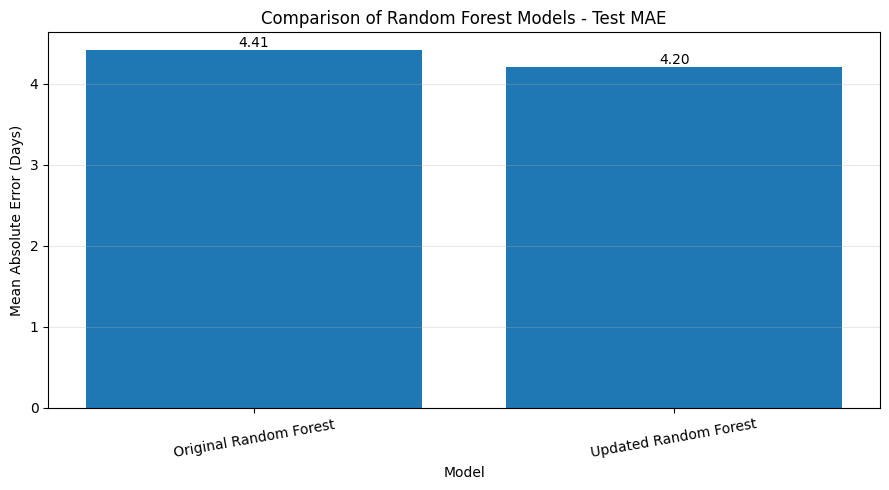

In [120]:
import matplotlib.pyplot as plt

# Model performance data
models_comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Updated Random Forest"
    ],
    "Test_MAE": [4.4113, mae_v2],
    "Test_RMSE": [5.7968, rmse_v2],
    "R2": [0.0348, r2_v2]
})

# Plot MAE comparison
plt.figure(figsize=(9, 5))

bars = plt.bar(
    models_comparison["Model"],
    models_comparison["Test_MAE"]
)

plt.title("Comparison of Random Forest Models - Test MAE")
plt.ylabel("Mean Absolute Error (Days)")
plt.xlabel("Model")
plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.2f}',
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    "outputs/figures/week4_model_mae_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [ ]:
# Simulate delivery-risk prioritisation

In [121]:
# Create operational prioritisation dataset
optimization_df = pd.DataFrame({
    "Actual_Delivery_Days": y_test_v2.values,
    "Predicted_Delivery_Days": predictions_v2,
    "Estimated_Delivery_Days": X_test_v2[
        "estimated_delivery_days"
    ].values
})

# Calculate predicted delay against promised window
optimization_df["Predicted_Delay_Days"] = (
    optimization_df["Predicted_Delivery_Days"]
    - optimization_df["Estimated_Delivery_Days"]
)

# Assign operational risk categories
optimization_df["Risk_Category"] = np.select(
    [
        optimization_df["Predicted_Delay_Days"] > 2,
        optimization_df["Predicted_Delay_Days"] > 0
    ],
    [
        "High Risk",
        "Medium Risk"
    ],
    default="Low Risk"
)

# Summarise risk categories
risk_summary = optimization_df.groupby(
    "Risk_Category"
).agg(
    Orders=("Predicted_Delivery_Days", "count"),
    Average_Predicted_Delay=(
        "Predicted_Delay_Days", "mean"
    ),
    Average_Actual_Delivery=(
        "Actual_Delivery_Days", "mean"
    )
).reset_index()

display(risk_summary.round(2))

print("Total test orders:", len(optimization_df))
print(
    "Risk category counts:\n",
    optimization_df["Risk_Category"].value_counts()
)

,Risk_Category,Orders,Average_Predicted_Delay,Average_Actual_Delivery
0,High Risk,164,2.94,4.98
1,Low Risk,18539,-10.83,8.91
2,Medium Risk,591,0.89,5.11


Total test orders: 19294
Risk category counts:
 Risk_Category
Low Risk       18539
Medium Risk      591
High Risk        164
Name: count, dtype: int64


In [ ]:
# Evaluate risk classification against actual delivery outcomes

In [122]:
# Calculate actual delay against estimated delivery window
optimization_df["Actual_Delay_Days"] = (
    optimization_df["Actual_Delivery_Days"]
    - optimization_df["Estimated_Delivery_Days"]
)

# Identify actual late deliveries
optimization_df["Actually_Late"] = (
    optimization_df["Actual_Delay_Days"] > 0
)

# Evaluate each predicted risk category
actual_risk_performance = optimization_df.groupby(
    "Risk_Category"
).agg(
    Total_Orders=("Actually_Late", "count"),
    Actually_Late_Orders=("Actually_Late", "sum"),
    Actual_Late_Rate=("Actually_Late", "mean"),
    Average_Actual_Delay=("Actual_Delay_Days", "mean")
).reset_index()

actual_risk_performance["Actual_Late_Rate"] *= 100

display(actual_risk_performance.round(2))

# Overall late delivery statistics
print(
    "Total actually late orders:",
    optimization_df["Actually_Late"].sum()
)

print(
    "Overall actual late rate:",
    round(optimization_df["Actually_Late"].mean() * 100, 2),
    "%"
)

,Risk_Category,Total_Orders,Actually_Late_Orders,Actual_Late_Rate,Average_Actual_Delay
0,High Risk,164,72,43.90,-0.14
1,Low Risk,18539,756,4.08,-13.11
2,Medium Risk,591,193,32.66,-0.25


Total actually late orders: 1021
Overall actual late rate: 5.29 %


In [ ]:
# Calculate risk detection performance

In [123]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# Treat High and Medium as flagged orders
optimization_df["Predicted_Late_Risk"] = (
    optimization_df["Risk_Category"].isin(
        ["High Risk", "Medium Risk"]
    )
)

# Actual late-delivery indicator
y_actual = optimization_df["Actually_Late"].astype(int)

# Predicted risk indicator
y_risk = optimization_df["Predicted_Late_Risk"].astype(int)

# Calculate confusion matrix
cm = confusion_matrix(y_actual, y_risk)

print("Confusion Matrix:")
print(cm)

print("\nRisk Detection Performance:")
print("Precision:", round(precision_score(y_actual, y_risk), 4))
print("Recall:", round(recall_score(y_actual, y_risk), 4))
print("F1 Score:", round(f1_score(y_actual, y_risk), 4))

print("\nClassification Report:")
print(classification_report(
    y_actual,
    y_risk,
    target_names=["Not Late", "Late"]
))

Confusion Matrix:
[[17783   490]
 [  756   265]]

Risk Detection Performance:
Precision: 0.351
Recall: 0.2595
F1 Score: 0.2984

Classification Report:
              precision    recall  f1-score   support

    Not Late       0.96      0.97      0.97     18273
        Late       0.35      0.26      0.30      1021

    accuracy                           0.94     19294
   macro avg       0.66      0.62      0.63     19294
weighted avg       0.93      0.94      0.93     19294



In [ ]:
# comparison of actual late-delivery rates across the three risk categories

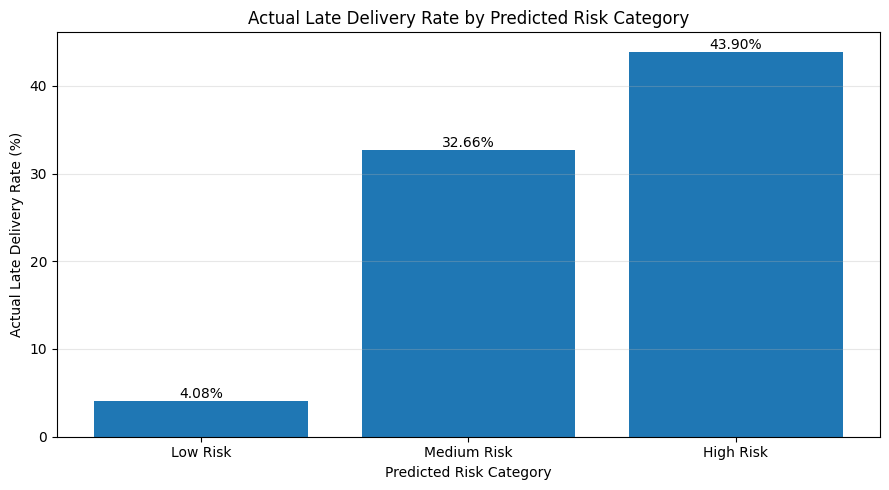

In [124]:
import matplotlib.pyplot as plt

# Calculate actual late rate by predicted risk category
risk_chart = optimization_df.groupby(
    "Risk_Category"
)["Actually_Late"].mean().reindex(
    ["Low Risk", "Medium Risk", "High Risk"]
) * 100

plt.figure(figsize=(9, 5))

bars = plt.bar(
    risk_chart.index,
    risk_chart.values
)

plt.title("Actual Late Delivery Rate by Predicted Risk Category")
plt.xlabel("Predicted Risk Category")
plt.ylabel("Actual Late Delivery Rate (%)")
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "outputs/figures/week4_risk_category_late_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()